Connected to Python 3.14.4

In [ ]:
# =====================================
# 🎉 energy planner project 🎉
# =====================================
# 개발 환경
# Python 3.14 (64 bit)
# LightGBM / XGBoost 최종 버전
#
# VS Code 실행 전
# Python: Select Interpreter
# → Python 3.14 (64 bit) 선택

#%% 🔥라이브러리
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import lightgbm as lgb
import xgboost as xgb

import holidays
import optuna
import xgboost
import joblib
import requests

from lightgbm import LGBMRegressor
from xgboost import XGBRegressor, callback
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error
)

from sklearn.metrics import (
    mean_absolute_error
)

c:\Users\PC\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
# =====================================
# Data Preprocessing (전처리)
# =====================================

In [ ]:
df_p15d = pd.read_csv('power_15m_data_202605271649.csv')

# meter_id별 데이터 개수 확인
print(df_p15d['meter_id'].value_counts())

meter_id
1    733716
2     17370
Name: count, dtype: int64


In [ ]:
df_p15d = df_p15d[
    (df_p15d['meter_id'] == 1)
    &
    (df_p15d['channel_no'] == 1)
]

# 확인
print(df_p15d[['meter_id', 'channel_no']].value_counts())

meter_id  channel_no
1         1             26057
Name: count, dtype: int64


In [ ]:
print(df_p15d.isnull().sum())

meter_id                0
channel_no              0
ts                      0
current_power_kw        0
kwh_this_month          0
kwh_last_month          0
kwh_sum                 0
daily_kwh               0
bill_15m                0
demand_kw           12849
dtype: int64


In [ ]:
df_p15d = df_p15d.drop(
    ['demand_kw', 'bill_15m'],
    axis=1,
    errors='ignore'
)

In [ ]:
#print(df_p15d.iloc[0])

In [ ]:
#df_p15d = df_p15d.iloc[1:].reset_index(drop=True)

# ♻️수정>>> 초, 밀리초 제거 > 데이터를 날짜와 시간 순서로 정렬 > 완전히 날짜와 시간 같은 중복된 데이터 확인 > 중복된 데이터 삭제 

In [ ]:
# ts 컬럼 datetime 변환
df_p15d['ts'] = pd.to_datetime(df_p15d['ts'])

# 초 + 밀리초 제거
df_p15d['ts'] = df_p15d['ts'].dt.floor('min')

# ts 기준 시간순 정렬
df_p15d = df_p15d.sort_values('ts')

# ts 중복 제거 
df_p15d = (
    df_p15d
    .drop_duplicates(
        subset='ts',
        keep='last'
    )
)

# 인덱스 초기화
df_p15d = df_p15d.reset_index(drop=True)

# 확인
print(df_p15d['ts'].head(10))

0   2025-08-20 11:30:00+09:00
1   2025-08-20 11:45:00+09:00
2   2025-08-20 12:00:00+09:00
3   2025-08-20 12:15:00+09:00
4   2025-08-20 12:30:00+09:00
5   2025-08-20 12:45:00+09:00
6   2025-08-20 13:00:00+09:00
7   2025-08-20 13:15:00+09:00
8   2025-08-20 13:30:00+09:00
9   2025-08-20 13:45:00+09:00
Name: ts, dtype: datetime64[us, UTC+09:00]


In [ ]:
# 전체 15분 시계열 생성
full_ts = pd.date_range(
    start=df_p15d['ts'].min(),
    end=df_p15d['ts'].max(),
    freq='15min'
)

# 누락된 시간 추출
missing_ts = full_ts.difference(
    df_p15d['ts']
)

print(
    f'전체 누락 시간 개수 : {len(missing_ts)}'
)

# 월별 누락 개수 집계
missing_month = pd.DataFrame({
    'month': missing_ts.to_period('M').astype(str)
})

print("\n월별 누락 시간 개수")
print(
    missing_month['month']
    .value_counts()
    .sort_index()
)

# ♻️수정 >>> ts에서 빈 날짜, 빈 시간대 확인 

전체 누락 시간 개수 : 927

월별 누락 시간 개수
month
2025-08     19
2025-09    472
2025-10    143
2025-11      3
2025-12      8
2026-01    275
2026-03      6
2026-05      1
Name: count, dtype: int64


<ipython-input-10-7bd57c1fef0b>:21: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  'month': missing_ts.to_period('M').astype(str)


In [ ]:
# 누적 전력량(kwh_sum) → 15분 사용량

# 시간 간격(분) 계산
df_p15d['time_diff'] = (
    df_p15d['ts']
    .diff()
    .dt.total_seconds()
    / 60
)

# 15분 간격일 때만 사용량 계산
df_p15d['kwh_15m'] = np.where(
    df_p15d['time_diff'] == 15,
    df_p15d['kwh_sum'].diff(),
    np.nan
)

# 계산 불가능 구간 제거
df_p15d = (
    df_p15d
    .dropna(subset=['kwh_15m'])
    .reset_index(drop=True)
)

# 확인
print(
    df_p15d[
        ['ts', 'time_diff', 'kwh_sum', 'kwh_15m']
    ].head()
)

                         ts  time_diff  kwh_sum  kwh_15m
0 2025-08-20 11:45:00+09:00       15.0    135.7      1.4
1 2025-08-20 12:00:00+09:00       15.0    137.0      1.3
2 2025-08-20 12:15:00+09:00       15.0    137.9      0.9
3 2025-08-20 12:30:00+09:00       15.0    138.7      0.8
4 2025-08-20 12:45:00+09:00       15.0    139.5      0.8


In [ ]:
# ts를 인덱스로 설정
df_hour = (
    df_p15d
    .set_index('ts')
    .resample('1h')
    .agg(
        kwh_1h=('kwh_15m', 'sum'),
        cnt=('kwh_15m', 'count')
    )
    .reset_index()
)

# 15분 데이터가 4개 모두 존재하는 시간만 사용
df_hour = df_hour[
    df_hour['cnt'] == 4
]

# (선택) 이후 feature 생성 시 cnt는 필요 없으므로 제거
df_hour = df_hour.drop(columns='cnt')

# 확인
print(df_hour.head())
print(df_hour.shape)

                         ts  kwh_1h
1 2025-08-20 12:00:00+09:00     3.8
2 2025-08-20 13:00:00+09:00     5.0
3 2025-08-20 14:00:00+09:00     5.2
4 2025-08-20 15:00:00+09:00     5.2
5 2025-08-20 16:00:00+09:00     5.1
(6435, 2)


In [ ]:
# 전체 기간(15분 간격) 생성
full_ts = pd.date_range(
    start=df_p15d['ts'].min(),
    end=df_p15d['ts'].max(),
    freq='15min'
)

# 실제 ts와 비교하여 누락된 시간 찾기
missing_ts = full_ts.difference(
    df_p15d['ts']
)

# 결과 출력
print(
    f'누락된 시간 개수 : {len(missing_ts)}'
)

if len(missing_ts) > 0:

    # 월(month) 컬럼 생성
    missing_df = pd.DataFrame({
        'month': missing_ts.to_period('M').astype(str)
    })

    print('\n월별 누락 시간 개수')

    print(
        missing_df['month']
        .value_counts()
        .sort_index()
    )

else:
    print('\n누락된 날짜 및 시간이 없습니다.')

누락된 시간 개수 : 988

월별 누락 시간 개수
month
2025-08     26
2025-09    498
2025-10    151
2025-11      6
2025-12     10
2026-01    288
2026-03      7
2026-05      2
Name: count, dtype: int64


<ipython-input-13-6a2c27442358>:24: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  'month': missing_ts.to_period('M').astype(str)


In [ ]:
full_hour = pd.date_range(
    start=df_hour['ts'].min(),
    end=df_hour['ts'].max(),
    freq='1h'
)

missing_hour = full_hour.difference(
    df_hour['ts']
)

print(
    f'1시간 단위 누락 개수 : {len(missing_hour)}'
)

1시간 단위 누락 개수 : 290


In [ ]:
# 누락된 시간대가 많은 달은 예측의 오차 발생 가능
# month
# 2025-09    144
# 2026-01     82
# 2025-10     42

# missing_hour : 누락된 1시간 datetime Index

missing_month = pd.DataFrame({
    'month': missing_hour.to_period('M').astype(str)
})

monthly_missing = (
    missing_month['month']
    .value_counts()          # 월별 누락 시간 개수
    .sort_values(ascending=False)   # 내림차순 정렬
)

print(monthly_missing)

month
2025-09    144
2026-01     82
2025-10     42
2025-08     10
2025-11      4
2025-12      4
2026-03      3
2026-05      1
Name: count, dtype: int64


<ipython-input-15-578ed2da7aaa>:11: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  'month': missing_hour.to_period('M').astype(str)


In [ ]:
# 하순(21~31일)    57
# 상순(1~10일)     16
# 중순(11~20일)     9

# missing_hour : 누락된 1시간 datetime Index

# DataFrame 생성
jan_missing = pd.DataFrame({
    'missing_ts': missing_hour
})

# 1월 데이터만 추출
jan_missing = jan_missing[
    jan_missing['missing_ts'].dt.month == 1
].copy()

# 일(day) 컬럼 생성
jan_missing['day'] = jan_missing['missing_ts'].dt.day

# 날짜별 누락 시간 개수
jan_dist = (
    jan_missing['day']
    .value_counts()
    .sort_index()
)

print("1월 날짜별 누락 시간 개수")
print(jan_dist)


# 상순 / 중순 / 하순 집계
# -------------------------------
jan_missing['period'] = np.where(
    jan_missing['day'] <= 10,
    '상순(1~10일)',
    np.where(
        jan_missing['day'] <= 20,
        '중순(11~20일)',
        '하순(21~31일)'
    )
)

print("\n1월 상·중·하순별 누락 시간 개수")
print(
    jan_missing['period']
    .value_counts()
)

1월 날짜별 누락 시간 개수
day
5      2
6      4
9     10
15     1
16     4
19     3
20     1
21     1
27    14
28    24
29    18
Name: count, dtype: int64

1월 상·중·하순별 누락 시간 개수
period
하순(21~31일)    57
상순(1~10일)     16
중순(11~20일)     9
Name: count, dtype: int64


In [ ]:
df_p15d.to_csv(
    'df_p15d.csv',
    index=False,
    encoding='utf-8-sig'
)

In [ ]:
# =====================================
# feature engineering
# =====================================

In [ ]:
# ts 컬럼에서 시간(hour) 추출 → 0~23 시간대 변수 생성

df_hour['hour'] = df_hour['ts'].dt.hour

# 확인
print(df_hour[['ts', 'hour']].head())

                         ts  hour
1 2025-08-20 12:00:00+09:00    12
2 2025-08-20 13:00:00+09:00    13
3 2025-08-20 14:00:00+09:00    14
4 2025-08-20 15:00:00+09:00    15
5 2025-08-20 16:00:00+09:00    16


In [ ]:
# ts 컬럼에서 요일(weekday) 추출
# Monday=0, Sunday=6 형태로 생성됨

df_hour['weekday'] = df_hour['ts'].dt.weekday

# 확인
print(df_hour[['ts', 'weekday']].head())

                         ts  weekday
1 2025-08-20 12:00:00+09:00        2
2 2025-08-20 13:00:00+09:00        2
3 2025-08-20 14:00:00+09:00        2
4 2025-08-20 15:00:00+09:00        2
5 2025-08-20 16:00:00+09:00        2


In [ ]:
# weekday를 기준으로 주말 여부 생성
# Saturday(5), Sunday(6) = 1 (주말), 그 외 = 0 (평일)

df_hour['is_weekend'] = (
    df_hour['weekday'].isin([5, 6])
).astype(int)

# 확인
print(
    df_hour[
        ['ts', 'weekday', 'is_weekend']
    ].head()
)

                         ts  weekday  is_weekend
1 2025-08-20 12:00:00+09:00        2           0
2 2025-08-20 13:00:00+09:00        2           0
3 2025-08-20 14:00:00+09:00        2           0
4 2025-08-20 15:00:00+09:00        2           0
5 2025-08-20 16:00:00+09:00        2           0


In [ ]:
# holidays.KR() : 한국 법정 공휴일 자동 제공

is_holiday = set(holidays.KR().keys())

# 노동절(5월 1일) 추가
labor_day = pd.to_datetime(
    ["2026-05-01"]
).date

# date 컬럼 생성 (없으면 추가)
df_hour['date'] = df_hour['ts'].dt.date

# 공휴일 여부 생성
df_hour['is_holiday'] = (
    df_hour['date'].isin(is_holiday)
    |
    df_hour['date'].isin(labor_day)
).astype(int)

# 확인
print(
    df_hour[
        ['ts', 'is_holiday']
    ].head()
)

                         ts  is_holiday
1 2025-08-20 12:00:00+09:00           0
2 2025-08-20 13:00:00+09:00           0
3 2025-08-20 14:00:00+09:00           0
4 2025-08-20 15:00:00+09:00           0
5 2025-08-20 16:00:00+09:00           0


In [ ]:
# ts 컬럼에서 월(month) 추출

df_hour['month'] = df_hour['ts'].dt.month

# 확인
print(df_hour[['ts', 'month']].head())

                         ts  month
1 2025-08-20 12:00:00+09:00      8
2 2025-08-20 13:00:00+09:00      8
3 2025-08-20 14:00:00+09:00      8
4 2025-08-20 15:00:00+09:00      8
5 2025-08-20 16:00:00+09:00      8


In [ ]:
# ts 컬럼에서 일(day) 추출

df_hour['day'] = df_hour['ts'].dt.day

# 확인
print(df_hour[['ts', 'day']].head())

                         ts  day
1 2025-08-20 12:00:00+09:00   20
2 2025-08-20 13:00:00+09:00   20
3 2025-08-20 14:00:00+09:00   20
4 2025-08-20 15:00:00+09:00   20
5 2025-08-20 16:00:00+09:00   20


In [ ]:
# df_hour(전력 사용량)과 df_temp(기온 데이터)를 안정적으로 결합하여 
# 온도 Feature를 생성하기 위한 전처리 과정

df_temp = pd.read_csv("gwangju_temp.csv")

# 전부 NaN 행 제거
df_temp = df_temp.dropna(how='all')

# date 문자열 정리
df_temp['date'] = df_temp['date'].astype(str).str.strip()

# datetime 변환 (안전 처리)
df_temp['date'] = pd.to_datetime(df_temp['date'], errors='coerce')

# NaT 제거
df_temp = df_temp.dropna(subset=['date'])

# 중복 제거 (중요)
df_temp = df_temp.drop_duplicates(subset=['date'])

# 날짜만 남기기 (timezone 제거 + key 통일)
df_temp['date'] = df_temp['date'].dt.floor('D').dt.date

In [ ]:
df_hour['ts'] = pd.to_datetime(df_hour['ts'])

df_hour['date'] = df_hour['ts'].dt.date

In [ ]:
df_hour = pd.merge(
    df_hour,
    df_temp,
    on='date',
    how='left'
)

In [ ]:
print("temp 결측 비율:", df_hour['avg_temp'].isna().mean())

temp 결측 비율: 0.0


In [ ]:
print(df_hour.columns)

Index(['ts', 'kwh_1h', 'hour', 'weekday', 'is_weekend', 'date', 'is_holiday',
       'month', 'day', 'avg_temp', 'daily_min_temp', 'daily_max_temp'],
      dtype='str')


In [ ]:
# 컬럼명 공백 제거
df_hour.columns = df_hour.columns.str.strip()

# --------------------------
# 1. ✨temp_range
# 일교차 (max - min)
df_hour['temp_range'] = (
    df_hour['daily_max_temp']
    - df_hour['daily_min_temp']
)


# --------------------------
# 2. ✨temp_centered
# 최근 7일 평균 대비 현재 기온 편차
# 7일 = 24 * 7 = 168시간
df_hour['temp_centered'] = (
    df_hour['avg_temp']
    - df_hour['avg_temp']
        .rolling(window=168, min_periods=1)
        .mean()
)


# --------------------------
# 3. ✨temp_ma_24 ✨temp_ma_168
# 1일 / 7일 이동평균
df_hour['temp_ma_24'] = (
    df_hour['avg_temp']
        .rolling(window=24, min_periods=1)
        .mean()
)

df_hour['temp_ma_168'] = (
    df_hour['avg_temp']
        .rolling(window=168, min_periods=1)
        .mean()
)


# --------------------------
# 4. ✨temp_diff_24 ✨temp_diff_168
# 1일 전 / 7일 전 대비 기온 변화
df_hour['temp_diff_24'] = (
    df_hour['avg_temp'].diff(24)
)

df_hour['temp_diff_168'] = (
    df_hour['avg_temp'].diff(168)
)


# --------------------------
# 5. ✨ Temperature Indicator

# 더운 날
df_hour['is_hot'] = (
    df_hour['avg_temp'] >= 28
).astype(int)

# 추운 날
df_hour['is_cold'] = (
    df_hour['avg_temp'] <= 5
).astype(int)

# 강한 추위
df_hour['is_very_cold'] = (
    df_hour['avg_temp'] <= 0
).astype(int)

# 극한 추위 (광주에서는 드문 이벤트)
df_hour['is_extreme_cold'] = (
    df_hour['avg_temp'] <= -3
).astype(int)

# 전일 대비 평균기온 변화량
df_hour['temp_diff_prev_day'] = (
    df_hour['avg_temp']
    - df_hour['avg_temp'].shift(24)
)

# 전일 대비 평균기온 5℃ 이상 하락
df_hour['is_temp_drop_5'] = (
    df_hour['temp_diff_prev_day'] <= -5
).astype(int)


# --------------------------
# 6. ✨cooling_degree ✨heating_degree
# 냉방/난방 필요도
df_hour['cooling_degree'] = (
    df_hour['avg_temp'] - 24
).clip(lower=0)

df_hour['heating_degree'] = (
    18 - df_hour['avg_temp']
).clip(lower=0)


# 확인
print(
    df_hour[
        [
            'ts',
            'avg_temp',
            'temp_range',
            'temp_centered',
            'temp_ma_24',
            'temp_ma_168',
            'temp_diff_24',
            'temp_diff_168'
        ]
    ].head()
)

                         ts  avg_temp  temp_range  temp_centered  temp_ma_24  \
0 2025-08-20 12:00:00+09:00      28.7         9.3            0.0        28.7   
1 2025-08-20 13:00:00+09:00      28.7         9.3            0.0        28.7   
2 2025-08-20 14:00:00+09:00      28.7         9.3            0.0        28.7   
3 2025-08-20 15:00:00+09:00      28.7         9.3            0.0        28.7   
4 2025-08-20 16:00:00+09:00      28.7         9.3            0.0        28.7   

   temp_ma_168  temp_diff_24  temp_diff_168  
0         28.7           NaN            NaN  
1         28.7           NaN            NaN  
2         28.7           NaN            NaN  
3         28.7           NaN            NaN  
4         28.7           NaN            NaN  


In [ ]:
# --------------------------
# 1시간 단위 예측용 Lag Feature

# 1시간 전
df_hour['lag_1'] = df_hour['kwh_1h'].shift(1)

# 1일 전 같은 시간
df_hour['lag_24'] = df_hour['kwh_1h'].shift(24)

# 1주일 전 같은 시간
df_hour['lag_168'] = df_hour['kwh_1h'].shift(168)

# --------------------------
# 결측 처리
# 가장 긴 lag(168) 기준 제거

df_hour = df_hour.iloc[168:].reset_index(drop=True)

# 확인
print(
    df_hour[
        ['ts', 'kwh_1h', 'lag_1', 'lag_24', 'lag_168']
    ].head()
)

                         ts  kwh_1h  lag_1  lag_24  lag_168
0 2025-08-27 22:00:00+09:00     0.9    0.7     1.4      3.8
1 2025-08-27 23:00:00+09:00     0.9    0.9     1.3      5.0
2 2025-08-28 00:00:00+09:00     0.8    0.9     1.4      5.2
3 2025-08-28 01:00:00+09:00     0.8    0.8     1.5      5.2
4 2025-08-28 02:00:00+09:00     0.7    0.8     1.3      5.1


In [ ]:
# --------------------------
# Rolling Feature 생성

# 최근 3시간 평균
df_hour['rolling_mean_3'] = (
    df_hour['kwh_1h']
    .rolling(window=3)
    .mean()
)

# 최근 6시간 평균
df_hour['rolling_mean_6'] = (
    df_hour['kwh_1h']
    .rolling(window=6)
    .mean()
)

# 최근 24시간 평균
df_hour['rolling_mean_24'] = (
    df_hour['kwh_1h']
    .rolling(window=24)
    .mean()
)

# 최근 24시간 최대값
df_hour['rolling_max_24'] = (
    df_hour['kwh_1h']
    .rolling(window=24)
    .max()
)

# 최근 24시간 최소값
df_hour['rolling_min_24'] = (
    df_hour['kwh_1h']
    .rolling(window=24)
    .min()
)

# --------------------------
# 결측 처리
# 가장 긴 rolling window(24) 기준 제거

df_hour = df_hour.iloc[24:].reset_index(drop=True)

# 확인
print(
    df_hour[
        [
            'ts',
            'kwh_1h',
            'rolling_mean_3',
            'rolling_mean_6',
            'rolling_mean_24'
        ]
    ].head()
)

                         ts  kwh_1h  rolling_mean_3  rolling_mean_6  \
0 2025-08-28 22:00:00+09:00     1.4        1.500000        2.566667   
1 2025-08-28 23:00:00+09:00     1.5        1.500000        1.866667   
2 2025-08-29 00:00:00+09:00     1.4        1.433333        1.466667   
3 2025-08-29 01:00:00+09:00     1.5        1.466667        1.483333   
4 2025-08-29 02:00:00+09:00     1.4        1.433333        1.466667   

   rolling_mean_24  
0         3.004167  
1         3.029167  
2         3.054167  
3         3.083333  
4         3.112500  


In [ ]:
# --------------------------
# Difference Feature 생성 (kwh_1h 기준)

# 직전 1시간 대비 변화량
df_hour['diff_1'] = df_hour['kwh_1h'].diff(1)

# 1일 전 동일 시간 대비 변화량
df_hour['diff_24'] = df_hour['kwh_1h'].diff(24)

# 1주일 전 동일 시간 대비 변화량
df_hour['diff_168'] = df_hour['kwh_1h'].diff(168)

# --------------------------
# 결측 처리
# 가장 큰 diff 기준(168) 이후 데이터 사용

df_hour = df_hour.iloc[168:].reset_index(drop=True)

# 확인
print(
    df_hour[
        [
            'ts',
            'kwh_1h',
            'diff_1',
            'diff_24',
            'diff_168'
        ]
    ].head()
)

                         ts  kwh_1h        diff_1  diff_24  diff_168
0 2025-09-06 10:00:00+09:00     1.3  2.273737e-13     -0.2      -0.1
1 2025-09-06 11:00:00+09:00     1.3 -2.273737e-13     -0.3      -0.2
2 2025-09-06 12:00:00+09:00     1.2 -1.000000e-01     -0.3      -0.2
3 2025-09-06 13:00:00+09:00     1.2 -2.273737e-13     -0.2      -0.3
4 2025-09-06 14:00:00+09:00     1.5  3.000000e-01      0.1       0.1


In [ ]:
df_hour.to_csv(
    'df_hour_v2.csv',
    index=False,
    encoding='utf-8-sig'
)

print("저장 완료 : df_hour_v2.csv")


# ♻️ 수정필요 >>> 볼 수 있는 형태로 변수들 저장

저장 완료 : df_hour_v2.csv


In [ ]:
# =====================================
# Walk-Forward Valid 만들기
# =====================================

In [ ]:
print(df_hour.shape)

print(df_hour.isnull().sum())

(6075, 37)
ts                    0
kwh_1h                0
hour                  0
weekday               0
is_weekend            0
date                  0
is_holiday            0
month                 0
day                   0
avg_temp              0
daily_min_temp        0
daily_max_temp        0
temp_range            0
temp_centered         0
temp_ma_24            0
temp_ma_168           0
temp_diff_24          0
temp_diff_168         0
is_hot                0
is_cold               0
is_very_cold          0
is_extreme_cold       0
temp_diff_prev_day    0
is_temp_drop_5        0
cooling_degree        0
heating_degree        0
lag_1                 0
lag_24                0
lag_168               0
rolling_mean_3        0
rolling_mean_6        0
rolling_mean_24       0
rolling_max_24        0
rolling_min_24        0
diff_1                0
diff_24               0
diff_168              0
dtype: int64


In [ ]:
# X : 모델이 학습에 사용할 Feature
# 제외 컬럼
# - ts      : 시계열 인덱스
# - date    : 날짜 key
# - kwh_1h  : 예측 대상(Target)

X = df_hour.drop(
    columns=[
        'ts',
        'date',
        'kwh_1h'
    ]
)

# y : 예측 대상
y = df_hour['kwh_1h']

# 확인
print("X shape :", X.shape)
print("y shape :", y.shape)

print("\n=== X columns ===")
print(X.columns.tolist())

print("\n=== Target ===")
print(y.head())

X shape : (6075, 34)
y shape : (6075,)

=== X columns ===
['hour', 'weekday', 'is_weekend', 'is_holiday', 'month', 'day', 'avg_temp', 'daily_min_temp', 'daily_max_temp', 'temp_range', 'temp_centered', 'temp_ma_24', 'temp_ma_168', 'temp_diff_24', 'temp_diff_168', 'is_hot', 'is_cold', 'is_very_cold', 'is_extreme_cold', 'temp_diff_prev_day', 'is_temp_drop_5', 'cooling_degree', 'heating_degree', 'lag_1', 'lag_24', 'lag_168', 'rolling_mean_3', 'rolling_mean_6', 'rolling_mean_24', 'rolling_max_24', 'rolling_min_24', 'diff_1', 'diff_24', 'diff_168']

=== Target ===
0    1.3
1    1.3
2    1.2
3    1.2
4    1.5
Name: kwh_1h, dtype: float64


In [ ]:
# --------------------------
# Train + CV
# 2025-08-20 ~ 2026-04-14
#
# Test
# 2026-04-15 ~ 2026-05-27
# --------------------------

folds = [

    (
        ('2025-08-20', '2025-10-31'),
        ('2025-11-01', '2025-11-30')
    ),

    (
        ('2025-08-20', '2025-11-30'),
        ('2025-12-01', '2025-12-31')
    ),

    (
        ('2025-08-20', '2025-12-31'),
        ('2026-01-01', '2026-01-31')
    ),

    (
        ('2025-08-20', '2026-01-31'),
        ('2026-02-01', '2026-02-28')
    ),

    (
        ('2025-08-20', '2026-02-28'),
        ('2026-03-01', '2026-03-31')
    ),

    (
        ('2025-08-20', '2026-03-31'),
        ('2026-04-01', '2026-04-14')
    )

]

In [ ]:
for i, (
    (train_start, train_end),
    (valid_start, valid_end)
) in enumerate(folds, start=1):

    train_mask = (
        (df_hour['ts'] >= train_start)
        &
        (df_hour['ts'] <= train_end)
    )

    valid_mask = (
        (df_hour['ts'] >= valid_start)
        &
        (df_hour['ts'] <= valid_end)
    )

    print(
        f'Fold {i} | '
        f'Train : {train_mask.sum():5d}개 '
        f'({train_start} ~ {train_end}) | '
        f'Valid : {valid_mask.sum():5d}개 '
        f'({valid_start} ~ {valid_end})'
    )

Fold 1 | Train :  1167개 (2025-08-20 ~ 2025-10-31) | Valid :   693개 (2025-11-01 ~ 2025-11-30)
Fold 2 | Train :  1877개 (2025-08-20 ~ 2025-11-30) | Valid :   718개 (2025-12-01 ~ 2025-12-31)
Fold 3 | Train :  2618개 (2025-08-20 ~ 2025-12-31) | Valid :   639개 (2026-01-01 ~ 2026-01-31)
Fold 4 | Train :  3279개 (2025-08-20 ~ 2026-01-31) | Valid :   649개 (2026-02-01 ~ 2026-02-28)
Fold 5 | Train :  3951개 (2025-08-20 ~ 2026-02-28) | Valid :   721개 (2026-03-01 ~ 2026-03-31)
Fold 6 | Train :  4695개 (2025-08-20 ~ 2026-03-31) | Valid :   313개 (2026-04-01 ~ 2026-04-14)


In [ ]:
cv_datasets = []

for fold_num, (train_period, valid_period) in enumerate(
    folds,
    start=1
):

    train_start, train_end = train_period
    valid_start, valid_end = valid_period

    # Train mask
    train_mask = (
        (df_hour['ts'] >= train_start)
        &
        (df_hour['ts'] <= train_end)
    )

    # Valid mask
    valid_mask = (
        (df_hour['ts'] >= valid_start)
        &
        (df_hour['ts'] <= valid_end)
    )

    # Dataset 생성
    X_train = X.loc[train_mask]
    y_train = y.loc[train_mask]

    X_valid = X.loc[valid_mask]
    y_valid = y.loc[valid_mask]

    cv_datasets.append({

        'fold': fold_num,

        'X_train': X_train,
        'y_train': y_train,

        'X_valid': X_valid,
        'y_valid': y_valid

    })

print("생성된 Fold 수 :", len(cv_datasets))

생성된 Fold 수 : 6


In [ ]:
# =====================================
# LightGBM Baseline Model
# =====================================

In [ ]:
lgbm_results = []      # Fold별 결과 저장 (list)
lgbm_models = []

print("LightGBM Fold 수 :", len(cv_datasets))

for fold_data in cv_datasets:

    # 1. Fold 데이터 불러오기
    fold_num = fold_data['fold']

    X_train = fold_data['X_train']
    y_train = fold_data['y_train']

    X_valid = fold_data['X_valid']
    y_valid = fold_data['y_valid']

    print(f"\n🚀 LightGBM Fold {fold_num}")

    # 2. 데이터 검증
    print(
        f"Train={X_train.shape}, "
        f"Valid={X_valid.shape}"
    )

    if len(X_train) == 0 or len(X_valid) == 0:
        print("❌ 데이터 없음")
        continue

    # 3. 모델 학습
    model = LGBMRegressor(
        objective='regression',
        n_estimators=1000,
        learning_rate=0.05,
        num_leaves=31,
        random_state=42
    )

    model.fit(X_train, y_train)

    # 모델 저장
    lgbm_models.append(model)

    # 4. 예측
    pred = model.predict(X_valid)

    # 5. 평가 지표 계산
    mae = mean_absolute_error(y_valid, pred)

    rmse = np.sqrt(
        mean_squared_error(y_valid, pred)
    )

    mape = (
        mean_absolute_percentage_error(
            y_valid,
            pred
        ) * 100
    )

    # 6. 결과 저장
    lgbm_results.append({
        'fold': fold_num,
        'MAE': mae,
        'RMSE': rmse,
        'MAPE': mape
    })

    # 7. Fold 결과 출력
    print(f"MAE  : {mae:.4f}")
    print(f"RMSE : {rmse:.4f}")
    print(f"MAPE : {mape:.2f}%")

LightGBM Fold 수 : 6

🚀 LightGBM Fold 1
Train=(1167, 34), Valid=(693, 34)
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000444 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2726
[LightGBM] [Info] Number of data points in the train set: 1167, number of used features: 28
[LightGBM] [Info] Start training from score 2.341474
MAE  : 0.1042
RMSE : 0.1834
MAPE : 3.97%

🚀 LightGBM Fold 2
Train=(1877, 34), Valid=(718, 34)
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000251 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3193
[LightGBM] [Info] Number of data points in the train set: 1877, number of used features: 28
[LightGBM] [Info] Start training from score 2.412999
MAE  : 0.0968
RMSE : 0.1606
MAPE : 3.64%

🚀 LightGBM Fold 3
Train=(2618, 34), Valid=(63

In [ ]:
lgbm_results_df = pd.DataFrame(lgbm_results)

print("\n=== LightGBM Baseline Summary ===")
print(lgbm_results_df)

print("\nAverage")
print(
    lgbm_results_df[
        ['MAE', 'RMSE', 'MAPE']
    ].mean()
)


=== LightGBM Baseline Summary ===
   fold       MAE      RMSE      MAPE
0     1  0.104201  0.183405  3.974299
1     2  0.096800  0.160582  3.637112
2     3  0.223453  0.486938  5.306139
3     4  0.062250  0.117955  2.108984
4     5  0.043063  0.079837  1.565101
5     6  0.049141  0.082938  1.970155

Average
MAE     0.096485
RMSE    0.185276
MAPE    3.093632
dtype: float64


In [ ]:
# === LightGBM Baseline Summary ===
#    fold       MAE      RMSE      MAPE
# 0     1  0.104201  0.183405  3.974299
# 1     2  0.096800  0.160582  3.637112
# 2     3  0.223453  0.486938  5.306139
# 3     4  0.062250  0.117955  2.108984
# 4     5  0.043063  0.079837  1.565101
# 5     6  0.049141  0.082938  1.970155

# Average
# MAE     0.096485
# RMSE    0.185276
# MAPE    3.093632
# dtype: float64

In [ ]:
#for fold_data in cv_datasets:
#
#    fold_num = fold_data['fold']
#
#    y_valid = fold_data['y_valid']
#
#    print(
#        f"Fold {fold_num} "
#        f"min={y_valid.min():.10f} "
#        f"max={y_valid.max():.4f}"
#    )

# --------------------------
# 분석 메모
# --------------------------
# 1. Fold 2, Fold 3에서 MAPE가 비정상적으로 크게 발생
#    → y_valid 최소값 확인 결과 0 kWh 존재
#    → MAPE 분모가 0이 되어 지표가 폭발한 것으로 판단
#
# 2. Fold 3에서 kwh_1h 최대값 188.1 확인
#    → 다른 Fold 최대값(약 6~12 수준) 대비 매우 큼
#    → 계량기 오류 / 누적치 차분 오류 / 실제 이벤트 여부 검증 필요
#
# 3. 다음 작업
#    (1) Fold 3 이상치(188.1 kWh) 검증
#    (2) Fold 2,3의 0 kWh 발생 원인 확인
# --------------------------


# =====================================
# 데이터 품질 개선
# =====================================


# -------------------------------------
# LightGBM Baseline 결과 분석 (♻️ 수정 필요)
# -------------------------------------
#
#  fold      MAE     RMSE         MAPE
#     1 0.214601 0.553940 6.108244e+00
#     2 0.226443 0.827104 5.512481e+14
#     3 0.706892 5.220498 2.999036e+15
#     4 0.327720 0.965823 7.831491e+00
#     5 0.066917 0.187341 2.219669e+00
#     6 0.091723 0.492256 2.787994e+00
#
# Average Score
# MAE     2.723825e-01
# RMSE    1.374494e+00
# MAPE    5.917140e+14
#
# Fold 1 min=0.9000000000 max=7.1000
# Fold 2 min=0.0000000000 max=12.1000
# Fold 3 min=0.0000000000 max=188.1000 ♻️
# Fold 4 min=1.0000000000 max=7.1000
# Fold 5 min=0.9000000000 max=6.7000
# Fold 6 min=1.2000000000 max=6.5000
# -------------------------------------

In [ ]:
# Fold 3 Validation 구간 최대 사용량 확인

# Fold 3 데이터 추출
#fold3 = cv_datasets[2]

# Validation 원본 데이터
#fold3_df = df_hour.loc[
#    fold3['y_valid'].index
#].copy()
#
# 사용량 내림차순 확인
#print(
#    fold3_df[
#        ['ts', 'kwh_1h']
#    ]
#    .sort_values(
#        'kwh_1h',
#        ascending=False
#    )
#    .head(20)
#)

In [ ]:
#df_p15d['time_diff'] = (
#    df_p15d['ts']
#    .diff()
#    .dt.total_seconds()
#    / 60
#)
#
#print(
#    df_p15d[
#        df_p15d['time_diff'] > 15
#    ][
#        ['ts', 'time_diff']
#    ]
#)

# -------------------------------------
# 분석 메모
# -------------------------------------
#
# Fold 3에서 kwh_1h 최대값 188.1 확인
#
# Fold 3 최대값(188.1 kWh) 이상치 원인 분석 완료
# 2026-01-29 17:45 이전에 장시간 데이터 공백(time_diff > 15분) 확인
# time_diff == 15 조건으로 kwh_15m 재생성 후 이상치 제거
# Fold 3 최대값 188.1 → 6.9 kWh로 정상화 확인


# -------------------------------------
# LightGBM Baseline 결과 분석 (♻️ 수정 필요)
# -------------------------------------
#
#  fold      MAE     RMSE         MAPE
#     1 0.137295 0.297410 4.788370e+00
#     2 0.127951 0.391537 5.300565e+14
#     3 0.273749 1.880313 3.045263e+15
#     4 0.102531 0.227661 3.683834e+00
#     5 0.047377 0.084719 1.891068e+00
#     6 0.046639 0.080832 1.881641e+00
#
# Average Score
# MAE     1.225904e-01
# RMSE    4.937451e-01
# MAPE    5.958866e+14
#
# Fold 1 min=0.9000000000 max=6.5000
# Fold 2 min=0.0000000000 max=7.3000
# Fold 3 min=-46.8000000000 ♻️ max=6.9000
# Fold 4 min=1.0000000000 max=7.1000
# Fold 5 min=0.9000000000 max=6.7000
# Fold 6 min=1.2000000000 max=6.5000
# -------------------------------------

In [ ]:
#
# 음수 사용량 발생 건수
print("음수 건수 :", (df_p15d['kwh_15m'] < 0).sum())
#
# 음수 사용량 전체 확인
#print(
#    df_p15d.loc[
#        df_p15d['kwh_15m'] < 0,
#        [
#            'ts',
#            'time_diff',
#            'kwh_sum',
#            'kwh_15m'
#        ]
#    ]
#)

음수 건수 : 18


In [ ]:
#
#dup_ts = df_p15d[
#    df_p15d.duplicated(
#        subset='ts',
#        keep=False
#    )
#]
#
#print("중복 행 수 :", len(dup_ts))
#
#print(
#    dup_ts[
#        ['ts', 'kwh_sum']
#    ]
#    .sort_values('ts')
#)

# -------------------------------------
# 분석 메모
# -------------------------------------
#
# 음수 사용량(kwh_15m < 0) 원인 조사
#
# 동일 ts에 서로 다른 kwh_sum 값이 중복 저장되어 있었음
# kwh_sum은 전체 기간 동안 정상 우상향으로 계량기 리셋 아님
# Fold 3 최소값(-46.8 kWh)은 데이터 중복에 의한 이상치로 판단
# ts 중복 제거 후 kwh_15m 및 df_hour 재생성 필요


# =====================================
# LightGBM Baseline 결과 분석 (♻️ 수정 필요)
# =====================================
#
#  fold      MAE     RMSE     MAPE
#     1 0.095296 0.165802 3.610072e+00
#     2 0.088568 0.154397 3.322567e+14 ♻️
#     3 0.196353 0.401435 3.157398e+15 ♻️
#     4 0.055305 0.091562 2.047781e+00
#     5 0.040926 0.071851 1.559780e+00
#     6 0.044616 0.078194 1.735451e+00
#
# Average Score
# MAE     8.684404e-02
# RMSE    1.605401e-01
# MAPE    5.816092e+14
#
# Fold 1 min=0.9000000000 max=6.5000
# Fold 2 min=0.0000000000 ♻️ max=7.3000
# Fold 3 min=0.0000000000 ♻️ max=6.9000
# Fold 4 min=1.0000000000 max=7.1000
# Fold 5 min=0.9000000000 max=6.7000
# Fold 6 min=1.2000000000 max=6.5000
# =====================================


# ♻️ 수정 필요
# 음수 사용량이 아직까지 나오는 부분 해결

In [ ]:
#for fold_num in [2, 3]:
#
#    fold = cv_datasets[fold_num - 1]
#
#    fold_df = df_hour.loc[
#        fold['y_valid'].index
#    ].copy()
#
#    zero_df = fold_df[
#        fold_df['kwh_1h'] == 0
#    ]
#
#    print("\n" + "=" * 50)
#    print(f"Fold {fold_num}")
#    print("=" * 50)
#    print("0 kWh 건수 :", len(zero_df))
#
#    print(
#        zero_df[
#            ['ts', 'kwh_1h']
#        ]
#        .sort_values('ts')
#    )

In [ ]:
#start_ts = '2026-01-09 04:00:00+09:00'
#end_ts   = '2026-01-09 16:00:00+09:00'

#print(
#    df_p15d[
#        (df_p15d['ts'] >= start_ts)
#        &
#        (df_p15d['ts'] <= end_ts)
#    ][
#        ['ts', 'kwh_sum', 'kwh_15m']
#    ]
#)

# =====================================
# 분석 메모
# =====================================
#
# Fold 2·3의 0 kWh 분석
#
# Fold 2(1건), Fold 3(65건)의 0 kWh 발생 원인을 조사함.
# 일부 시간대는 15분 사용량 데이터가 4개 미만인 상태로
# 1시간 사용량(kwh_1h)이 집계됨.
# 정상적으로 15분 데이터 4개가 존재하는 시간대만 사용하도록
# 전처리를 수정함.
# 재검증 결과 Fold 2·3의 0 kWh 문제가 해소되었으며
# MAPE도 정상 수준으로 안정화됨.


# =====================================
# LightGBM Baseline 결과 분석
# =====================================
#
#  fold      MAE     RMSE     MAPE
#     1 0.104201 0.183405 3.974299
#     2 0.096800 0.160582 3.637112
#     3 0.223453 0.486938 5.306139
#     4 0.061830 0.117460 2.099196
#     5 0.043157 0.080009 1.563095
#     6 0.049141 0.082938 1.970155
#
# Average Score
# MAE     0.096430
# RMSE    0.185222
# MAPE    3.091666
# dtype: float64
#
# Fold 1 min=0.9000000000 max=6.5000
# Fold 2 min=1.0000000000 max=7.3000
# Fold 3 min=1.0000000000 max=6.9000
# Fold 4 min=1.0000000000 max=7.1000
# Fold 5 min=0.9000000000 max=6.7000
# Fold 6 min=1.2000000000 max=6.5000
# =====================================





# ♻️ 수정 >>> 중복된 검증 과정, 위에서 이미 해결된 것들은 '주석' 처리


# ============================================================
# Walk-Forward Validation Summary
# ============================================================
#  fold      MAE     RMSE     MAPE
#     1 0.106506 0.186180 4.086201
#     2 0.099970 0.169492 3.674308
#     3 0.224844 0.490714 5.355929
#     4 0.063080 0.124320 2.112341
#     5 0.043944 0.081108 1.612410
#     6 0.047613 0.080228 1.884227

# Average Score
# MAE     0.097660
# RMSE    0.188674
# MAPE    3.120902
# dtype: float64

In [ ]:
# =====================================
# Baseline Model Comparison
# =====================================

In [ ]:
xgb_results = []
xgb_models = []

print("XGBoost Fold 수 :", len(cv_datasets))

for fold_data in cv_datasets:

    fold_num = fold_data['fold']

    X_train = fold_data['X_train']
    y_train = fold_data['y_train']

    X_valid = fold_data['X_valid']
    y_valid = fold_data['y_valid']

    print(f"\n🚀 XGBoost Fold {fold_num}")

    model = XGBRegressor(
        objective='reg:squarederror',
        n_estimators=1000,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y_train)

    pred = model.predict(X_valid)

    xgb_models.append(model)

    xgb_results.append({

        'fold': fold_num,
        'MAE': mean_absolute_error(y_valid, pred),
        'RMSE': np.sqrt(
            mean_squared_error(y_valid, pred)
        ),
        'MAPE': (
            mean_absolute_percentage_error(
                y_valid,
                pred
            ) * 100
        )

    })

XGBoost Fold 수 : 6

🚀 XGBoost Fold 1

🚀 XGBoost Fold 2

🚀 XGBoost Fold 3

🚀 XGBoost Fold 4

🚀 XGBoost Fold 5

🚀 XGBoost Fold 6


In [ ]:
xgb_results_df = pd.DataFrame(xgb_results)

print("\n=== XGBoost Baseline Summary ===")
print(xgb_results_df)

print("\nAverage")
print(xgb_results_df[['MAE','RMSE','MAPE']].mean())


=== XGBoost Baseline Summary ===
   fold       MAE      RMSE      MAPE
0     1  0.102725  0.178254  3.911719
1     2  0.091399  0.159332  3.331666
2     3  0.193160  0.407660  4.963964
3     4  0.068256  0.126575  2.235854
4     5  0.043228  0.076554  1.541570
5     6  0.039174  0.065631  1.479487

Average
MAE     0.089657
RMSE    0.169001
MAPE    2.910710
dtype: float64


In [ ]:
# === XGBoost Baseline Summary ===
#    fold       MAE      RMSE      MAPE
# 0     1  0.102725  0.178254  3.911719
# 1     2  0.091399  0.159332  3.331666
# 2     3  0.193160  0.407660  4.963964
# 3     4  0.068256  0.126575  2.235854
# 4     5  0.043228  0.076554  1.541570
# 5     6  0.039174  0.065631  1.479487

# Average
# MAE     0.089657
# RMSE    0.169001
# MAPE    2.910710
# dtype: float64

In [ ]:
comparison_df = pd.DataFrame({

    'Model': [
        'LightGBM Baseline',
        'XGBoost Baseline'
    ],

    'MAE': [
        lgbm_results_df['MAE'].mean(),
        xgb_results_df['MAE'].mean()
    ],

    'RMSE': [
        lgbm_results_df['RMSE'].mean(),
        xgb_results_df['RMSE'].mean()
    ],

    'MAPE': [
        lgbm_results_df['MAPE'].mean(),
        xgb_results_df['MAPE'].mean()
    ]

})

print("\n")
print("=" * 60)
print("Baseline Model Comparison(Fold 평균치)")
print("=" * 60)

print(
    comparison_df.round(6).to_string(index=False)
)

# MAE 기준 최고 성능 모델
best_model = comparison_df.loc[
    comparison_df['MAE'].idxmin(),
    'Model'
]

best_mae = comparison_df.loc[
    comparison_df['MAE'].idxmin(),
    'MAE'
]

print("\nBest Baseline Model")
print(
    f"{best_model} "
    f"(MAE = {best_mae:.6f})"
)



Baseline Model Comparison(Fold 평균치)
            Model      MAE     RMSE     MAPE
LightGBM Baseline 0.096485 0.185276 3.093632
 XGBoost Baseline 0.089657 0.169001 2.910710

Best Baseline Model
XGBoost Baseline (MAE = 0.089657)


In [ ]:
# ---------------
#             Model      MAE     RMSE     MAPE
# LightGBM Baseline 0.096485 0.185276 3.093632
#  XGBoost Baseline 0.089657 0.169001 2.910710

# Best Baseline Model
# XGBoost Baseline (MAE = 0.089657)

In [ ]:
# =====================================
# Feature Reduced Model
# =====================================

In [ ]:
print("\n")
print("=" * 60)
print("Current Features")
print("=" * 60)

print(list(X.columns))

print("\nTotal Features :", len(X.columns))



Current Features
['hour', 'weekday', 'is_weekend', 'is_holiday', 'month', 'day', 'avg_temp', 'daily_min_temp', 'daily_max_temp', 'temp_range', 'temp_centered', 'temp_ma_24', 'temp_ma_168', 'temp_diff_24', 'temp_diff_168', 'is_hot', 'is_cold', 'is_very_cold', 'is_extreme_cold', 'temp_diff_prev_day', 'is_temp_drop_5', 'cooling_degree', 'heating_degree', 'lag_1', 'lag_24', 'lag_168', 'rolling_mean_3', 'rolling_mean_6', 'rolling_mean_24', 'rolling_max_24', 'rolling_min_24', 'diff_1', 'diff_24', 'diff_168']

Total Features : 34


In [ ]:
lgbm_model = lgbm_models[-1]
xgb_model = xgb_models[-1]

In [ ]:
lgbm_importance = pd.DataFrame({

    'feature': X.columns,
    'importance': lgbm_model.feature_importances_

})

# 중요도 내림차순 정렬
lgbm_importance = lgbm_importance.sort_values(
    by='importance',
    ascending=False
)

# --------------------------
# Top 20
# --------------------------
print("\n")
print("=" * 60)
print("LightGBM Top 20 Features")
print("=" * 60)

print(
    lgbm_importance.head(20)
)



LightGBM Top 20 Features
            feature  importance
31           diff_1        5565
23            lag_1        3900
26   rolling_mean_3        3519
32          diff_24        1970
27   rolling_mean_6        1817
33         diff_168        1600
24           lag_24        1441
25          lag_168        1404
29   rolling_max_24         997
28  rolling_mean_24         964
0              hour         785
10    temp_centered         747
14    temp_diff_168         672
13     temp_diff_24         652
30   rolling_min_24         644
11       temp_ma_24         567
9        temp_range         518
5               day         513
12      temp_ma_168         478
8    daily_max_temp         314


In [ ]:
lgbm_importance = pd.DataFrame({

    'Rank': range(
        1,
        len(X.columns) + 1
    ),

    'Feature': lgbm_model.feature_name_,

    'Importance':
    lgbm_model.feature_importances_

})

lgbm_importance = lgbm_importance.sort_values(
    by='Importance',
    ascending=False
).reset_index(drop=True)

# Rank 재부여
lgbm_importance['Rank'] = (
    lgbm_importance.index + 1
)

print("\n=== LightGBM Feature Importance Ranking ===")
print(
    lgbm_importance.to_string(
        index=False
    )
)


=== LightGBM Feature Importance Ranking ===
 Rank            Feature  Importance
    1             diff_1        5565
    2              lag_1        3900
    3     rolling_mean_3        3519
    4            diff_24        1970
    5     rolling_mean_6        1817
    6           diff_168        1600
    7             lag_24        1441
    8            lag_168        1404
    9     rolling_max_24         997
   10    rolling_mean_24         964
   11               hour         785
   12      temp_centered         747
   13      temp_diff_168         672
   14       temp_diff_24         652
   15     rolling_min_24         644
   16         temp_ma_24         567
   17         temp_range         518
   18                day         513
   19        temp_ma_168         478
   20     daily_max_temp         314
   21     daily_min_temp         289
   22           avg_temp         274
   23            weekday         234
   24              month         136
   25         is_weekend      

In [ ]:
zero_importance = lgbm_importance[
    lgbm_importance['Importance'] == 0
]

print("\n=== LightGBM Importance = 0 Features ===")
print(
    zero_importance.to_string(
        index=False
    )
)

print(
    f"\n총 {len(zero_importance)}개의 Feature가 "
    "Importance = 0 입니다."
)


=== LightGBM Importance = 0 Features ===
 Rank            Feature  Importance
   25         is_weekend           0
   26         is_holiday           0
   27       is_very_cold           0
   28            is_cold           0
   29             is_hot           0
   30     heating_degree           0
   31    is_extreme_cold           0
   32 temp_diff_prev_day           0
   33     is_temp_drop_5           0
   34     cooling_degree           0

총 10개의 Feature가 Importance = 0 입니다.


In [ ]:
xgb_importance = pd.DataFrame({

    'Feature': X.columns,

    'Importance':
    xgb_model.feature_importances_

})

# 중요도 내림차순 정렬
xgb_importance = xgb_importance.sort_values(
    by='Importance',
    ascending=False
).reset_index(drop=True)

# Rank 부여
xgb_importance.insert(
    0,
    'Rank',
    xgb_importance.index + 1
)

print("\n=== XGBoost Feature Importance Ranking ===")
print(
    xgb_importance.to_string(
        index=False
    )
)


=== XGBoost Feature Importance Ranking ===
 Rank            Feature  Importance
    1     rolling_mean_3    0.649835
    2              lag_1    0.172269
    3             diff_1    0.114856
    4     rolling_mean_6    0.021295
    5            diff_24    0.010262
    6           diff_168    0.008950
    7     rolling_max_24    0.007114
    8     rolling_min_24    0.003153
    9            lag_168    0.003007
   10             lag_24    0.002586
   11    is_extreme_cold    0.001619
   12               hour    0.001265
   13           avg_temp    0.000423
   14                day    0.000312
   15       temp_diff_24    0.000290
   16        temp_ma_168    0.000271
   17            weekday    0.000263
   18         temp_ma_24    0.000249
   19         is_weekend    0.000243
   20     daily_min_temp    0.000229
   21         temp_range    0.000224
   22              month    0.000223
   23      temp_diff_168    0.000200
   24     daily_max_temp    0.000199
   25    rolling_mean_24    0.0

In [ ]:
zero_importance = xgb_importance[
    xgb_importance['Importance'] == 0
]

print("\n=== XGBoost Importance = 0 Features ===")
print(
    zero_importance.to_string(
        index=False
    )
)

print(
    f"\n총 {len(zero_importance)}개의 Feature가 "
    "Importance = 0 입니다."
)


=== XGBoost Importance = 0 Features ===
 Rank      Feature  Importance
   32 is_very_cold         0.0
   33   is_holiday         0.0
   34       is_hot         0.0

총 3개의 Feature가 Importance = 0 입니다.


In [ ]:
print("\n=== XGBoost Bottom 10 Features ===")

print(
    xgb_importance.tail(10).to_string(
        index=False
    )
)


=== XGBoost Bottom 10 Features ===
 Rank            Feature  Importance
   25    rolling_mean_24    0.000197
   26      temp_centered    0.000139
   27 temp_diff_prev_day    0.000125
   28     heating_degree    0.000121
   29     cooling_degree    0.000054
   30            is_cold    0.000020
   31     is_temp_drop_5    0.000006
   32       is_very_cold    0.000000
   33         is_holiday    0.000000
   34             is_hot    0.000000


In [ ]:
drop_features = [

    'daily_max_temp',
    'temp_range',
    'temp_ma_168',
    'temp_ma_24',
    'temp_diff_168',
    'temp_diff_24',
    'temp_centered',
    'day'
]

# Feature 제거
X_reduced = X.drop(columns=drop_features)

print("기존 Feature 개수:", X.shape[1])
print("축소 후 Feature 개수:", X_reduced.shape[1])
print("\n제거된 Feature:", drop_features)

기존 Feature 개수: 34
축소 후 Feature 개수: 26

제거된 Feature: ['daily_max_temp', 'temp_range', 'temp_ma_168', 'temp_ma_24', 'temp_diff_168', 'temp_diff_24', 'temp_centered', 'day']


In [ ]:
feature_columns = X_reduced.columns.tolist()

import json

with open("feature_columns.json", "w") as f:
    json.dump(feature_columns, f)

In [ ]:
lgbm_reduced_results = []

for fold_data in cv_datasets:

    fold_num = fold_data['fold']

    # reduced feature 적용 (중요)
    X_train = fold_data['X_train'][X_reduced.columns]
    X_valid = fold_data['X_valid'][X_reduced.columns]

    y_train = fold_data['y_train']
    y_valid = fold_data['y_valid']

    model = LGBMRegressor(
        n_estimators=500,
        learning_rate=0.05,
        random_state=42
    )

    model.fit(X_train, y_train)

    pred = model.predict(X_valid)

    lgbm_reduced_results.append({

        'fold': fold_num,
        'MAE': mean_absolute_error(y_valid, pred),
        'RMSE': np.sqrt(mean_squared_error(y_valid, pred)),
        'MAPE': mean_absolute_percentage_error(y_valid, pred) * 100
    })

print("LightGBM Reduced 완료")



# XGBoost Retrain (Reduced Feature)


xgb_reduced_results = []

for fold_data in cv_datasets:

    fold_num = fold_data['fold']

    # reduced feature 적용
    X_train = fold_data['X_train'][X_reduced.columns]
    X_valid = fold_data['X_valid'][X_reduced.columns]

    y_train = fold_data['y_train']
    y_valid = fold_data['y_valid']

    model = XGBRegressor(

        objective='reg:squarederror',

        n_estimators=1000,
        learning_rate=0.05,

        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,

        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y_train)

    pred = model.predict(X_valid)

    xgb_reduced_results.append({

        'fold': fold_num,
        'MAE': mean_absolute_error(y_valid, pred),
        'RMSE': np.sqrt(mean_squared_error(y_valid, pred)),
        'MAPE': mean_absolute_percentage_error(y_valid, pred) * 100
    })

print("XGBoost Reduced 완료")

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000107 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1738
[LightGBM] [Info] Number of data points in the train set: 1167, number of used features: 20
[LightGBM] [Info] Start training from score 2.341474
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000155 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2110
[LightGBM] [Info] Number of data points in the train set: 1877, number of used features: 20
[LightGBM] [Info] Start training from score 2.412999
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000316 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2324
[LightGBM] [Info] Number of data points in the train set: 2618, number of used features: 24
[LightGBM] [Info] Start traini

In [ ]:
lgbm_red_df = pd.DataFrame(lgbm_reduced_results)
xgb_red_df = pd.DataFrame(xgb_reduced_results)

In [ ]:
# -----------------------------
print("\n")
print("=" * 60)
print("LightGBM Reduced Model")
print("=" * 60)
print("(Feature Reduction 적용 후)\n")

print(
    lgbm_red_df.to_string(
        index=False
    )
)

print("\nAverage Score")
print(
    lgbm_red_df[
        ['MAE', 'RMSE', 'MAPE']
    ].mean()
)



LightGBM Reduced Model
(Feature Reduction 적용 후)

 fold      MAE     RMSE     MAPE
    1 0.093199 0.171045 3.597037
    2 0.093941 0.158704 3.498739
    3 0.224253 0.491225 5.310514
    4 0.061560 0.116492 2.090925
    5 0.044317 0.081442 1.612817
    6 0.048766 0.081403 1.960189

Average Score
MAE     0.094339
RMSE    0.183385
MAPE    3.011703
dtype: float64


In [ ]:
# -----------------------------
print("\n")
print("=" * 60)
print("XGBoost Reduced Model")
print("=" * 60)
print("(Feature Reduction 적용 후)\n")

print(
    xgb_red_df.to_string(
        index=False
    )
)

print("\nAverage Score")
print(
    xgb_red_df[
        ['MAE', 'RMSE', 'MAPE']
    ].mean()
)



XGBoost Reduced Model
(Feature Reduction 적용 후)

 fold      MAE     RMSE     MAPE
    1 0.092734 0.158413 3.710427
    2 0.083568 0.147096 3.063510
    3 0.193475 0.413385 4.922202
    4 0.078458 0.139611 2.543759
    5 0.044030 0.072421 1.579560
    6 0.043266 0.071003 1.615747

Average Score
MAE     0.089255
RMSE    0.166988
MAPE    2.905867
dtype: float64


In [ ]:
# -----------------------------
comparison_df = pd.DataFrame({

    'Model': [
        'LightGBM Reduced',
        'XGBoost Reduced'
    ],

    'MAE': [
        lgbm_red_df['MAE'].mean(),
        xgb_red_df['MAE'].mean()
    ],

    'RMSE': [
        lgbm_red_df['RMSE'].mean(),
        xgb_red_df['RMSE'].mean()
    ],

    'MAPE': [
        lgbm_red_df['MAPE'].mean(),
        xgb_red_df['MAPE'].mean()
    ]

})

print("\n")
print("=" * 60)
print("Feature Reduced Model Comparison")
print("=" * 60)

print(
    comparison_df.to_string(
        index=False
    )
)

best_model = comparison_df.loc[
    comparison_df['MAE'].idxmin(),
    'Model'
]

best_mae = comparison_df['MAE'].min()

print("\nBest Reduced Model")
print(
    f"{best_model} "
    f"(MAE = {best_mae:.6f})"
)



Feature Reduced Model Comparison
           Model      MAE     RMSE     MAPE
LightGBM Reduced 0.094339 0.183385 3.011703
 XGBoost Reduced 0.089255 0.166988 2.905867

Best Reduced Model
XGBoost Reduced (MAE = 0.089255)


In [ ]:
# XGBoost Reduced Model
# -------------------------
# (Feature Reduction 적용 후)
# 
#  fold      MAE     RMSE     MAPE
#     1 0.092734 0.158413 3.710427
#     2 0.083568 0.147096 3.063510
#     3 0.193475 0.413385 4.922202
#     4 0.078458 0.139611 2.543759
#     5 0.044030 0.072421 1.579560
#     6 0.043266 0.071003 1.615747
# 
# Average Score
# MAE     0.089255
# RMSE    0.166988
# MAPE    2.905867
# dtype: float64


# =====================================
# Reduced XGBoost Hyper Parameter Tuning
# =====================================

In [ ]:
# ============================================================
# XGBoost (Reduced Feature) Optuna
# ============================================================

In [ ]:
FEATURES = X_reduced.columns

In [ ]:
# ============================================================
# 🚀 Objective Function
# ============================================================

def objective(trial):

    params = {

        # -------------------------
        # 기본 설정
        # -------------------------
        "objective": "reg:squarederror",
        "eval_metric": "mae",

        # -------------------------
        # Baseline 주변 탐색
        # Baseline :
        # max_depth = 6
        # lr = 0.05
        # subsample = 0.8
        # colsample = 0.8
        # -------------------------

        "max_depth": trial.suggest_int(
            "max_depth",
            4,
            8
        ),

        "min_child_weight": trial.suggest_int(
            "min_child_weight",
            1,
            8
        ),

        "subsample": trial.suggest_float(
            "subsample",
            0.75,
            1.00
        ),

        "colsample_bytree": trial.suggest_float(
            "colsample_bytree",
            0.75,
            1.00
        ),

        "eta": trial.suggest_float(
            "learning_rate",
            0.03,
            0.07
        ),

        "gamma": trial.suggest_float(
            "gamma",
            0.0,
            2.0
        ),

        "alpha": trial.suggest_float(
            "reg_alpha",
            0.0,
            1.0
        ),

        "lambda": trial.suggest_float(
            "reg_lambda",
            1.0,
            5.0
        ),

        "seed": 42,

        "verbosity": 0
    }

    fold_mae = []


    # ========================================================
    # Walk Forward Validation
    # ========================================================

    for fold in cv_datasets:

        X_train = fold['X_train'][FEATURES]
        y_train = fold['y_train']

        X_valid = fold['X_valid'][FEATURES]
        y_valid = fold['y_valid']

        dtrain = xgb.DMatrix(
            X_train,
            label=y_train
        )

        dvalid = xgb.DMatrix(
            X_valid,
            label=y_valid
        )

        model = xgb.train(

            params=params,

            dtrain=dtrain,

            # 충분히 크게 주고
            # Early Stopping이 자동 결정
            num_boost_round=3000,

            evals=[
                (dvalid, "valid")
            ],

            early_stopping_rounds=100,

            verbose_eval=False

        )

        pred = model.predict(dvalid)

        mae = mean_absolute_error(
            y_valid,
            pred
        )

        fold_mae.append(mae)

    return np.mean(fold_mae)

In [ ]:
# ============================================================
# 🚀 Optuna Study
# ============================================================

study = optuna.create_study(

    direction="minimize",

    sampler=optuna.samplers.TPESampler(
        seed=42
    )

)

study.optimize(

    objective,

    n_trials=150,

    show_progress_bar=True

)

[I 2026-06-11 16:10:46,249] A new study created in memory with name: no-name-2f3fe848-fc7e-4740-aa47-050fec98ded3
Best trial: 0. Best value: 0.122537:   1%|          | 1/150 [00:01<02:40,  1.08s/it]

[I 2026-06-11 16:10:47,328] Trial 0 finished with value: 0.12253652786317902 and parameters: {'max_depth': 5, 'min_child_weight': 8, 'subsample': 0.9329984854528512, 'colsample_bytree': 0.8996646210492591, 'learning_rate': 0.03624074561769746, 'gamma': 0.3119890406724053, 'reg_alpha': 0.05808361216819946, 'reg_lambda': 4.46470458309974}. Best is trial 0 with value: 0.12253652786317902.


Best trial: 1. Best value: 0.119821:   1%|▏         | 2/150 [00:02<02:29,  1.01s/it]

[I 2026-06-11 16:10:48,293] Trial 1 finished with value: 0.11982115032078278 and parameters: {'max_depth': 7, 'min_child_weight': 6, 'subsample': 0.7551461235739506, 'colsample_bytree': 0.9924774630404986, 'learning_rate': 0.06329770563201687, 'gamma': 0.4246782213565523, 'reg_alpha': 0.18182496720710062, 'reg_lambda': 1.7336180394137353}. Best is trial 1 with value: 0.11982115032078278.


Best trial: 2. Best value: 0.117731:   2%|▏         | 3/150 [00:03<02:44,  1.12s/it]

[I 2026-06-11 16:10:49,542] Trial 2 finished with value: 0.11773075448159083 and parameters: {'max_depth': 5, 'min_child_weight': 5, 'subsample': 0.8579862546605289, 'colsample_bytree': 0.8228072850495105, 'learning_rate': 0.05447411578889518, 'gamma': 0.27898772130408367, 'reg_alpha': 0.29214464853521815, 'reg_lambda': 2.465447373174767}. Best is trial 2 with value: 0.11773075448159083.


... (290 outputs left out)

Best trial: 136. Best value: 0.0824237:  99%|█████████▉| 149/150 [04:40<00:02,  2.28s/it]

[I 2026-06-11 16:15:27,162] Trial 148 finished with value: 0.14454987399893524 and parameters: {'max_depth': 6, 'min_child_weight': 8, 'subsample': 0.9142808837629958, 'colsample_bytree': 0.9085206395626728, 'learning_rate': 0.030057317824222413, 'gamma': 1.854557266601749, 'reg_alpha': 0.09305256319852914, 'reg_lambda': 2.2059871535673206}. Best is trial 136 with value: 0.08242374273571536.


Best trial: 136. Best value: 0.0824237: 100%|██████████| 150/150 [04:42<00:00,  1.89s/it]

[I 2026-06-11 16:15:29,078] Trial 149 finished with value: 0.10699286534553763 and parameters: {'max_depth': 6, 'min_child_weight': 7, 'subsample': 0.8788541635708627, 'colsample_bytree': 0.8802616450187439, 'learning_rate': 0.032032108187829526, 'gamma': 0.14892839598719784, 'reg_alpha': 0.11146794373645487, 'reg_lambda': 2.0579465964688852}. Best is trial 136 with value: 0.08242374273571536.


In [ ]:
# ============================================================
# 🚀 Best Result
# ============================================================

print("\n")
print("=" * 60)
print("XGBoost Reduced Feature Optuna")
print("=" * 60)

print(
    f"\nBest MAE : "
    f"{study.best_value:.6f}"
)

print("\nBest Params")

for k, v in study.best_params.items():
    print(
        f"{k:20s} : {v}"
    )



XGBoost Reduced Feature Optuna

Best MAE : 0.082424

Best Params
max_depth            : 6
min_child_weight     : 7
subsample            : 0.9301179450250081
colsample_bytree     : 0.8232531973601875
learning_rate        : 0.03131927532096039
gamma                : 0.0005931471574848002
reg_alpha            : 0.09366448339517872
reg_lambda           : 2.2164040594401406


In [ ]:
# ============================================================
# 이후 Optuna를 다시 돌리지 않고
# 최적 파라미터를 재사용하기 위함
# ============================================================

import json

with open(
    "best_xgb_reduced_params.json",
    "w"
) as f:

    json.dump(
        study.best_params,
        f,
        indent=4
    )

print("\nBest Parameters 저장 완료")
print("파일명 : best_xgb_reduced_params.json")    


Best Parameters 저장 완료
파일명 : best_xgb_reduced_params.json


In [ ]:
import json

with open(
    "best_xgb_reduced_params.json",
    "r"
) as f:

    best_params = json.load(f)

print("\nBest Parameters")
print(best_params)


Best Parameters
{'max_depth': 6, 'min_child_weight': 7, 'subsample': 0.9301179450250081, 'colsample_bytree': 0.8232531973601875, 'learning_rate': 0.03131927532096039, 'gamma': 0.0005931471574848002, 'reg_alpha': 0.09366448339517872, 'reg_lambda': 2.2164040594401406}


In [ ]:
# ============================================================
# XGBoost Reduced Feature Optuna Summary
# ============================================================

# Best MAE : 0.082424

# Best Params
# max_depth            : 6
# min_child_weight     : 7
# subsample            : 0.9301179450250081
# colsample_bytree     : 0.8232531973601875
# learning_rate        : 0.03131927532096039
# gamma                : 0.0005931471574848002
# reg_alpha            : 0.09366448339517872
# reg_lambda           : 2.2164040594401406

In [ ]:
# =====================================
# Reduced LightGBM Hyper Parameter Tuning
# =====================================

In [ ]:
FEATURES = X_reduced.columns

In [ ]:
def objective(trial):

    # ============================================================
    # 🔧 Hyperparameter Search Space
    # ============================================================
    params = {

        "objective": "regression",
        "metric": "mae",
        "verbosity": -1,

        # tree complexity
        "num_leaves": trial.suggest_int("num_leaves", 16, 128),
        "max_depth": trial.suggest_int("max_depth", 3, 10),
        "min_data_in_leaf": trial.suggest_int("min_data_in_leaf", 10, 100),

        # sampling
        "feature_fraction": trial.suggest_float("feature_fraction", 0.6, 1.0),
        "bagging_fraction": trial.suggest_float("bagging_fraction", 0.6, 1.0),
        "bagging_freq": trial.suggest_int("bagging_freq", 1, 5),

        # learning rate
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.08),

        # regularization
        "lambda_l1": trial.suggest_float("lambda_l1", 0, 3),
        "lambda_l2": trial.suggest_float("lambda_l2", 0, 6),

        "random_state": 42
    }

    fold_mae = []

    # ============================================================
    # 🚀 3. Walk-Forward Validation Loop
    # ============================================================
    for fold in cv_datasets:

        # -----------------------
        # Train / Valid split
        # -----------------------
        X_train = fold["X_train"][FEATURES]
        y_train = fold["y_train"]

        X_valid = fold["X_valid"][FEATURES]
        y_valid = fold["y_valid"]

        # -----------------------
        # Model 생성
        # -----------------------
        model = lgb.LGBMRegressor(
            **params,
            n_estimators=5000   # 충분히 크게 설정 (early stopping으로 제어)
        )

        # -----------------------
        # Early Stopping 학습
        # -----------------------
        model.fit(
            X_train,
            y_train,
            eval_set=[(X_valid, y_valid)],
            eval_metric="mae",
            callbacks=[
                lgb.early_stopping(stopping_rounds=50, verbose=False)
            ]
        )

        # -----------------------
        # Prediction + MAE 계산
        # -----------------------
        pred = model.predict(X_valid)
        mae = mean_absolute_error(y_valid, pred)

        fold_mae.append(mae)

    # ============================================================
    # 평균 MAE 반환
    # ============================================================
    return np.mean(fold_mae)

In [ ]:
study = optuna.create_study(direction="minimize")

study.optimize(
    objective,
    n_trials=50
)

[I 2026-06-11 16:15:29,225] A new study created in memory with name: no-name-58adc179-e29c-41b1-b8f4-7a2c3405c721
[I 2026-06-11 16:15:32,156] Trial 0 finished with value: 0.09763959859505796 and parameters: {'num_leaves': 82, 'max_depth': 9, 'min_data_in_leaf': 31, 'feature_fraction': 0.7185065832755864, 'bagging_fraction': 0.72071040960862, 'bagging_freq': 1, 'learning_rate': 0.05114937906446452, 'lambda_l1': 1.2570572191937361, 'lambda_l2': 1.3791238026608676}. Best is trial 0 with value: 0.09763959859505796.
[I 2026-06-11 16:15:34,182] Trial 1 finished with value: 0.10544182693115446 and parameters: {'num_leaves': 34, 'max_depth': 6, 'min_data_in_leaf': 52, 'feature_fraction': 0.6916285821552799, 'bagging_fraction': 0.64571632164641, 'bagging_freq': 5, 'learning_rate': 0.046173337701217204, 'lambda_l1': 1.9513114432132035, 'lambda_l2': 3.019219815915748}. Best is trial 0 with value: 0.09763959859505796.
[I 2026-06-11 16:15:35,699] Trial 2 finished with value: 0.11023838552463716 and

In [ ]:
print("\nBest MAE:", study.best_value)

print("\nBest Params:")
print(study.best_params)


Best MAE: 0.08370969185313794

Best Params:
{'num_leaves': 16, 'max_depth': 6, 'min_data_in_leaf': 17, 'feature_fraction': 0.8437733683713681, 'bagging_fraction': 0.8668961966135946, 'bagging_freq': 3, 'learning_rate': 0.04597748209726574, 'lambda_l1': 0.2008487758093355, 'lambda_l2': 3.48007807693795}


In [ ]:
# ============================================================

import json

with open(
    "best_lgbm_reduced_params.json",
    "w"
) as f:

    json.dump(
        study.best_params,
        f,
        indent=4
    )

print("\nBest Parameters 저장 완료")
print(
    "파일명 : "
    "best_lgbm_reduced_params.json"
)


Best Parameters 저장 완료
파일명 : best_lgbm_reduced_params.json


In [ ]:
import json

with open(
    "best_lgbm_reduced_params.json",
    "r"
) as f:

    best_params = json.load(f)

print("\nBest Parameters")
print(best_params)


Best Parameters
{'num_leaves': 16, 'max_depth': 6, 'min_data_in_leaf': 17, 'feature_fraction': 0.8437733683713681, 'bagging_fraction': 0.8668961966135946, 'bagging_freq': 3, 'learning_rate': 0.04597748209726574, 'lambda_l1': 0.2008487758093355, 'lambda_l2': 3.48007807693795}


In [ ]:
# ============================================================
# LightGBM Reduced Feature Optuna Summary
# ============================================================

# Best MAE : 0.085645

# Best Params
# num_leaves          : 76
# max_depth           : 8
# min_data_in_leaf    : 19
# feature_fraction    : 0.8121774778639154
# bagging_fraction    : 0.7488290805954028
# bagging_freq        : 2
# learning_rate       : 0.024749383011002223
# lambda_l1           : 0.2270636670030471
# lambda_l2           : 2.9027933806035042

In [ ]:
# =====================================
# Final XGBoost Model Training
# =====================================

In [ ]:
# ============================================================
# Reduced Feature + Optuna Best Parameter
# 전체 데이터로 최종 모델 생성
# ============================================================

FINAL_FEATURES = X_reduced.columns

X_final = X_reduced.copy()
y_final = y.copy()

final_xgb_model = XGBRegressor(

    objective='reg:squarederror',

    n_estimators=1000,
    learning_rate=0.03131927532096039,

    max_depth=6,
    min_child_weight=7,

    subsample=0.9301179450250081,
    colsample_bytree=0.8232531973601875,

    gamma=0.0005931471574848002,
    reg_alpha=0.09366448339517872,
    reg_lambda=2.2164040594401406,

    random_state=42,
    n_jobs=-1
)

final_xgb_model.fit(
    X_final,
    y_final
)

print("\n")
print("=" * 60)
print("Final XGBoost Model Training Complete")
print("=" * 60)
print(f"Feature Count : {len(FINAL_FEATURES)}")
print(f"Training Data : {X_final.shape}")



Final XGBoost Model Training Complete
Feature Count : 26
Training Data : (6075, 26)


In [ ]:
# ----------------------------------------
# Optuna 최적 파라미터
# ----------------------------------------
best_params = {

    "objective": "reg:squarederror",

    "max_depth": 6,
    "min_child_weight": 7,

    "subsample": 0.9301179450250081,
    "colsample_bytree": 0.8232531973601875,

    "learning_rate": 0.03131927532096039,

    "gamma": 0.0005931471574848002,
    "reg_alpha": 0.09366448339517872,
    "reg_lambda": 2.2164040594401406,

    "n_estimators": 1000,

    "random_state": 42,
    "n_jobs": -1
}


# ----------------------------------------
# Reduced Feature 전체 데이터 학습
# ----------------------------------------
final_model = XGBRegressor(
    **best_params
)

final_model.fit(
    X_reduced,
    y
)


# ----------------------------------------
# 모델 저장
# ----------------------------------------
joblib.dump(
    final_model,
    "xgb_reduced_optuna.pkl"
)

# ----------------------------------------
# Feature 목록도 함께 저장
# (추후 Recursive Forecast에서 반드시 필요)
# ----------------------------------------
joblib.dump(
    list(X_reduced.columns),
    "xgb_reduced_features.pkl"
)

print("\n")
print("=" * 60)
print("Final Model Save Complete")
print("=" * 60)
print("Model File   : xgb_reduced_optuna.pkl")
print("Feature File : xgb_reduced_features.pkl")



Final Model Save Complete
Model File   : xgb_reduced_optuna.pkl
Feature File : xgb_reduced_features.pkl


In [ ]:
# =====================================
# Recursive Forecast Function
# =====================================

In [ ]:
print(X_reduced.columns.tolist())

['hour', 'weekday', 'is_weekend', 'is_holiday', 'month', 'avg_temp', 'daily_min_temp', 'is_hot', 'is_cold', 'is_very_cold', 'is_extreme_cold', 'temp_diff_prev_day', 'is_temp_drop_5', 'cooling_degree', 'heating_degree', 'lag_1', 'lag_24', 'lag_168', 'rolling_mean_3', 'rolling_mean_6', 'rolling_mean_24', 'rolling_max_24', 'rolling_min_24', 'diff_1', 'diff_24', 'diff_168']


In [ ]:
SERVICE_KEY = "3051400f79d73b21ca9410905793c769eef55c17cb2e4e5e4579a4638d923dc1"

def get_forecast_temperature():

    url = (
        "http://apis.data.go.kr/"
        "1360000/"
        "VilageFcstInfoService_2.0/"
        "getVilageFcst"
    )

    params = {

        "serviceKey": SERVICE_KEY,

        "pageNo": "1",

        "numOfRows": "500",

        "dataType": "JSON",

        # 예시
        "base_date": "20260608",
        "base_time": "0500",

        # 광주
        "nx": "58",
        "ny": "74"
    }

    response = requests.get(
        url,
        params=params
    )

    items = response.json()[
        "response"
    ][
        "body"
    ][
        "items"
    ][
        "item"
    ]

    temp_list = []

    for item in items:

        if item["category"] == "TMP":

            dt = pd.to_datetime(

                item["fcstDate"]
                +
                item["fcstTime"],

                format="%Y%m%d%H%M"

            )

            temp_list.append({

                "ts": dt,

                "forecast_temp":
                float(
                    item["fcstValue"]
                )

            })

    return pd.DataFrame(
        temp_list
    )

In [ ]:
forecast_temp_df = get_forecast_temperature()

print(
    forecast_temp_df.head()
)

KeyError: 'body'

In [ ]:
# Final XGBoost Model 전용
# X_reduced.columns 기준


def recursive_forecast_24h(
    model,
    history_df,
    feature_cols,
    forecast_temp_df
):

    future_preds = []

    temp_df = history_df.copy()

    kr_holidays = holidays.KR()

    for step in range(24):

        # ==================================================
        # 다음 시점
        # ==================================================
        next_ts = (
            temp_df.iloc[-1]["ts"]
            + pd.Timedelta(hours=1)
        )

        row = {}

        row["ts"] = next_ts
        row["date"] = next_ts.date()

        # ==================================================
        # Calendar Feature
        # ==================================================
        row["hour"] = next_ts.hour
        row["weekday"] = next_ts.weekday()

        row["is_weekend"] = int(
            row["weekday"] >= 5
        )

        row["is_holiday"] = int(
            row["date"] in kr_holidays
        )

        row["month"] = next_ts.month

        # ==================================================
        # Temperature Feature
        # ==================================================

        forecast_row = forecast_temp_df[
            forecast_temp_df["ts"] == next_ts
        ]

        if not forecast_row.empty:

            avg_temp = (
                forecast_row[
                    "forecast_temp"
                ].values[0]
            )

        else:

            # API 값이 없으면 직전 값 사용
            avg_temp = (
                temp_df["avg_temp"]
                .iloc[-1]
            )

        row["avg_temp"] = avg_temp
        row["daily_min_temp"] = avg_temp

        row["is_hot"] = int(
            avg_temp >= 28
        )

        row["is_cold"] = int(
            avg_temp <= 5
        )

        row["is_very_cold"] = int(
            avg_temp <= 0
        )

        row["is_extreme_cold"] = int(
            avg_temp <= -3
        )

        row["temp_diff_prev_day"] = (
            avg_temp
            - temp_df.iloc[-24]["avg_temp"]
        )

        row["is_temp_drop_5"] = int(
            row["temp_diff_prev_day"] <= -5
        )

        row["cooling_degree"] = max(
            avg_temp - 24,
            0
        )

        row["heating_degree"] = max(
            18 - avg_temp,
            0
        )

        # ==================================================
        # Lag Feature
        # ==================================================
        row["lag_1"] = (
            temp_df.iloc[-1]["kwh_1h"]
        )

        row["lag_24"] = (
            temp_df.iloc[-24]["kwh_1h"]
        )

        row["lag_168"] = (
            temp_df.iloc[-168]["kwh_1h"]
        )

        # ==================================================
        # Rolling Feature
        # ==================================================
        row["rolling_mean_3"] = (
            temp_df["kwh_1h"]
            .tail(3)
            .mean()
        )

        row["rolling_mean_6"] = (
            temp_df["kwh_1h"]
            .tail(6)
            .mean()
        )

        row["rolling_mean_24"] = (
            temp_df["kwh_1h"]
            .tail(24)
            .mean()
        )

        row["rolling_max_24"] = (
            temp_df["kwh_1h"]
            .tail(24)
            .max()
        )

        row["rolling_min_24"] = (
            temp_df["kwh_1h"]
            .tail(24)
            .min()
        )

        # ==================================================
        # Diff Feature
        # ==================================================
        row["diff_1"] = (
            temp_df.iloc[-1]["kwh_1h"]
            - temp_df.iloc[-2]["kwh_1h"]
        )

        row["diff_24"] = (
            temp_df.iloc[-1]["kwh_1h"]
            - temp_df.iloc[-24]["kwh_1h"]
        )

        row["diff_168"] = (
            temp_df.iloc[-1]["kwh_1h"]
            - temp_df.iloc[-168]["kwh_1h"]
        )

        # ==================================================
        # Predict
        # ==================================================
        X_pred = pd.DataFrame(
            [row]
        )[feature_cols]

        pred = model.predict(
            X_pred
        )[0]

        row["kwh_1h"] = pred

        future_preds.append(row)

        # ==================================================
        # 다음 예측을 위해 append
        # ==================================================
        temp_df = pd.concat(
            [
                temp_df,
                pd.DataFrame([row])
            ],
            ignore_index=True
        )

    return pd.DataFrame(
        future_preds
    )

: 

In [ ]:
future_24h = recursive_forecast_24h(
    model=final_model,
    history_df=df_hour,
    feature_cols=X_reduced.columns,
    forecast_temp_df=forecast_temp_df
)

print(
    future_24h[
        ["ts", "kwh_1h"]
    ]
)

: 

In [ ]:
print(X_reduced.columns.tolist())

['hour', 'weekday', 'is_weekend', 'is_holiday', 'month', 'avg_temp', 'daily_min_temp', 'is_hot', 'is_cold', 'is_very_cold', 'is_extreme_cold', 'temp_diff_prev_day', 'is_temp_drop_5', 'cooling_degree', 'heating_degree', 'lag_1', 'lag_24', 'lag_168', 'rolling_mean_3', 'rolling_mean_6', 'rolling_mean_24', 'rolling_max_24', 'rolling_min_24', 'diff_1', 'diff_24', 'diff_168']


In [ ]:
# Final XGBoost Model 전용
# X_reduced.columns 기준


def recursive_forecast_24h(
    model,
    history_df,
    feature_cols,
    forecast_temp_df
):

    future_preds = []

    temp_df = history_df.copy()

    kr_holidays = holidays.KR()

    for step in range(24):

        # ==================================================
        # 다음 시점
        # ==================================================
        next_ts = (
            temp_df.iloc[-1]["ts"]
            + pd.Timedelta(hours=1)
        )

        row = {}

        row["ts"] = next_ts
        row["date"] = next_ts.date()

        # ==================================================
        # Calendar Feature
        # ==================================================
        row["hour"] = next_ts.hour
        row["weekday"] = next_ts.weekday()

        row["is_weekend"] = int(
            row["weekday"] >= 5
        )

        row["is_holiday"] = int(
            row["date"] in kr_holidays
        )

        row["month"] = next_ts.month

        # ==================================================
        # Temperature Feature
        # ==================================================

        forecast_row = forecast_temp_df[
            forecast_temp_df["ts"] == next_ts
        ]

        if not forecast_row.empty:

            avg_temp = (
                forecast_row[
                    "forecast_temp"
                ].values[0]
            )

        else:

            # API 값이 없으면 직전 값 사용
            avg_temp = (
                temp_df["avg_temp"]
                .iloc[-1]
            )

        row["avg_temp"] = avg_temp
        row["daily_min_temp"] = avg_temp

        row["is_hot"] = int(
            avg_temp >= 28
        )

        row["is_cold"] = int(
            avg_temp <= 5
        )

        row["is_very_cold"] = int(
            avg_temp <= 0
        )

        row["is_extreme_cold"] = int(
            avg_temp <= -3
        )

        row["temp_diff_prev_day"] = (
            avg_temp
            - temp_df.iloc[-24]["avg_temp"]
        )

        row["is_temp_drop_5"] = int(
            row["temp_diff_prev_day"] <= -5
        )

        row["cooling_degree"] = max(
            avg_temp - 24,
            0
        )

        row["heating_degree"] = max(
            18 - avg_temp,
            0
        )

        # ==================================================
        # Lag Feature
        # ==================================================
        row["lag_1"] = (
            temp_df.iloc[-1]["kwh_1h"]
        )

        row["lag_24"] = (
            temp_df.iloc[-24]["kwh_1h"]
        )

        row["lag_168"] = (
            temp_df.iloc[-168]["kwh_1h"]
        )

        # ==================================================
        # Rolling Feature
        # ==================================================
        row["rolling_mean_3"] = (
            temp_df["kwh_1h"]
            .tail(3)
            .mean()
        )

        row["rolling_mean_6"] = (
            temp_df["kwh_1h"]
            .tail(6)
            .mean()
        )

        row["rolling_mean_24"] = (
            temp_df["kwh_1h"]
            .tail(24)
            .mean()
        )

        row["rolling_max_24"] = (
            temp_df["kwh_1h"]
            .tail(24)
            .max()
        )

        row["rolling_min_24"] = (
            temp_df["kwh_1h"]
            .tail(24)
            .min()
        )

        # ==================================================
        # Diff Feature
        # ==================================================
        row["diff_1"] = (
            temp_df.iloc[-1]["kwh_1h"]
            - temp_df.iloc[-2]["kwh_1h"]
        )

        row["diff_24"] = (
            temp_df.iloc[-1]["kwh_1h"]
            - temp_df.iloc[-24]["kwh_1h"]
        )

        row["diff_168"] = (
            temp_df.iloc[-1]["kwh_1h"]
            - temp_df.iloc[-168]["kwh_1h"]
        )

        # ==================================================
        # Predict
        # ==================================================
        X_pred = pd.DataFrame(
            [row]
        )[feature_cols]

        pred = model.predict(
            X_pred
        )[0]

        row["kwh_1h"] = pred

        future_preds.append(row)

        # ==================================================
        # 다음 예측을 위해 append
        # ==================================================
        temp_df = pd.concat(
            [
                temp_df,
                pd.DataFrame([row])
            ],
            ignore_index=True
        )

    return pd.DataFrame(
        future_preds
    )

In [ ]:
future_24h = recursive_forecast_24h(
    model=final_model,
    history_df=df_hour,
    feature_cols=X_reduced.columns,
    forecast_temp_df=forecast_temp_df
)

print(
    future_24h[
        ["ts", "kwh_1h"]
    ]
)

NameError: name 'forecast_temp_df' is not defined

In [ ]:
# Final XGBoost Model 전용
# X_reduced.columns 기준


def recursive_forecast_24h(
    model,
    history_df,
    feature_cols
):

    future_preds = []

    temp_df = history_df.copy()

    kr_holidays = holidays.KR()

    for step in range(24):

        # ==================================================
        # 다음 시점
        # ==================================================
        next_ts = (
            temp_df.iloc[-1]["ts"]
            + pd.Timedelta(hours=1)
        )

        row = {}

        row["ts"] = next_ts
        row["date"] = next_ts.date()

        # ==================================================
        # Calendar Feature
        # ==================================================
        row["hour"] = next_ts.hour
        row["weekday"] = next_ts.weekday()

        row["is_weekend"] = int(
            row["weekday"] >= 5
        )

        row["is_holiday"] = int(
            row["date"] in kr_holidays
        )

        row["month"] = next_ts.month

        # ==================================================
        # Temperature Feature
        # ==================================================

        forecast_row = forecast_temp_df[
            forecast_temp_df["ts"] == next_ts
        ]

        if not forecast_row.empty:

            avg_temp = (
                forecast_row[
                    "forecast_temp"
                ].values[0]
            )

        else:

            # API 값이 없으면 직전 값 사용
            avg_temp = (
                temp_df["avg_temp"]
                .iloc[-1]
            )

        row["avg_temp"] = avg_temp
        row["daily_min_temp"] = avg_temp

        row["is_hot"] = int(
            avg_temp >= 28
        )

        row["is_cold"] = int(
            avg_temp <= 5
        )

        row["is_very_cold"] = int(
            avg_temp <= 0
        )

        row["is_extreme_cold"] = int(
            avg_temp <= -3
        )

        row["temp_diff_prev_day"] = (
            avg_temp
            - temp_df.iloc[-24]["avg_temp"]
        )

        row["is_temp_drop_5"] = int(
            row["temp_diff_prev_day"] <= -5
        )

        row["cooling_degree"] = max(
            avg_temp - 24,
            0
        )

        row["heating_degree"] = max(
            18 - avg_temp,
            0
        )

        # ==================================================
        # Lag Feature
        # ==================================================
        row["lag_1"] = (
            temp_df.iloc[-1]["kwh_1h"]
        )

        row["lag_24"] = (
            temp_df.iloc[-24]["kwh_1h"]
        )

        row["lag_168"] = (
            temp_df.iloc[-168]["kwh_1h"]
        )

        # ==================================================
        # Rolling Feature
        # ==================================================
        row["rolling_mean_3"] = (
            temp_df["kwh_1h"]
            .tail(3)
            .mean()
        )

        row["rolling_mean_6"] = (
            temp_df["kwh_1h"]
            .tail(6)
            .mean()
        )

        row["rolling_mean_24"] = (
            temp_df["kwh_1h"]
            .tail(24)
            .mean()
        )

        row["rolling_max_24"] = (
            temp_df["kwh_1h"]
            .tail(24)
            .max()
        )

        row["rolling_min_24"] = (
            temp_df["kwh_1h"]
            .tail(24)
            .min()
        )

        # ==================================================
        # Diff Feature
        # ==================================================
        row["diff_1"] = (
            temp_df.iloc[-1]["kwh_1h"]
            - temp_df.iloc[-2]["kwh_1h"]
        )

        row["diff_24"] = (
            temp_df.iloc[-1]["kwh_1h"]
            - temp_df.iloc[-24]["kwh_1h"]
        )

        row["diff_168"] = (
            temp_df.iloc[-1]["kwh_1h"]
            - temp_df.iloc[-168]["kwh_1h"]
        )

        # ==================================================
        # Predict
        # ==================================================
        X_pred = pd.DataFrame(
            [row]
        )[feature_cols]

        pred = model.predict(
            X_pred
        )[0]

        row["kwh_1h"] = pred

        future_preds.append(row)

        # ==================================================
        # 다음 예측을 위해 append
        # ==================================================
        temp_df = pd.concat(
            [
                temp_df,
                pd.DataFrame([row])
            ],
            ignore_index=True
        )

    return pd.DataFrame(
        future_preds
    )

In [ ]:
future_24h = recursive_forecast_24h(
    model=final_model,
    history_df=df_hour,
    feature_cols=X_reduced.columns,
    forecast_temp_df=forecast_temp_df
)

print(
    future_24h[
        ["ts", "kwh_1h"]
    ]
)

NameError: name 'forecast_temp_df' is not defined

In [ ]:
future_24h = recursive_forecast_24h(
    model=final_model,
    history_df=df_hour,
    feature_cols=X_reduced.columns,
)

print(
    future_24h[
        ["ts", "kwh_1h"]
    ]
)

NameError: name 'forecast_temp_df' is not defined

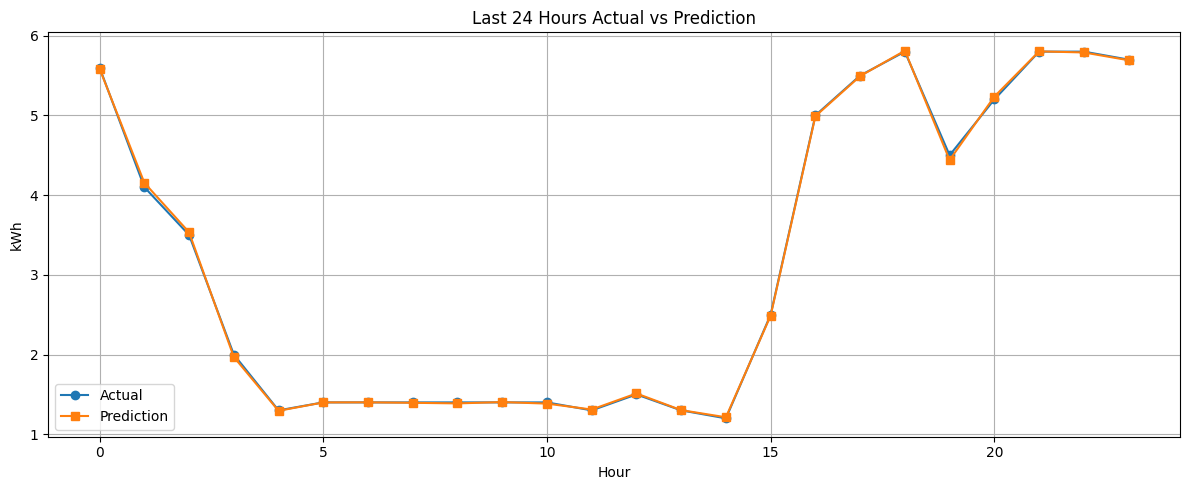

In [ ]:
# 마지막 24시간

X_last = X_reduced.iloc[-24:]
y_last = y.iloc[-24:]

# 예측

y_pred = final_model.predict(X_last)

plt.figure(figsize=(12,5))

plt.plot(
    range(24),
    y_last.values,
    marker='o',
    label='Actual'
)

plt.plot(
    range(24),
    y_pred,
    marker='s',
    label='Prediction'
)

plt.title(
    'Last 24 Hours Actual vs Prediction'
)

plt.xlabel('Hour')
plt.ylabel('kWh')

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

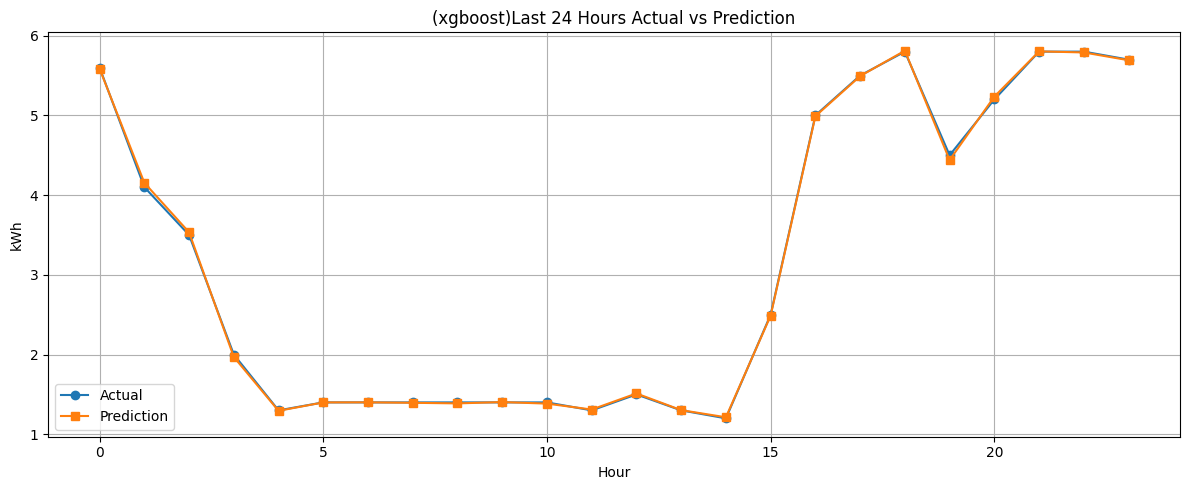

In [ ]:
# 마지막 24시간

X_last = X_reduced.iloc[-24:]
y_last = y.iloc[-24:]

# 예측

y_pred = final_model.predict(X_last)

plt.figure(figsize=(12,5))

plt.plot(
    range(24),
    y_last.values,
    marker='o',
    label='Actual'
)

plt.plot(
    range(24),
    y_pred,
    marker='s',
    label='Prediction'
)

plt.title(
    '(xgboost)Last 24 Hours Actual vs Prediction'
)

plt.xlabel('Hour')
plt.ylabel('kWh')

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
final_model.eval()

with torch.no_grad():

    # 가장 마지막 Sequence
    X_last = X_seq[-1]

    X_last = torch.tensor(
        X_last,
        dtype=torch.float32
    ).unsqueeze(0).to(device)

    pred_scaled = final_model(X_last)

# 역정규화
pred_24h = target_scaler.inverse_transform(
    pred_scaled.cpu().numpy().reshape(-1, 1)
).flatten()

# 실제 마지막 24시간
actual_24h = target_scaler.inverse_transform(
    y_seq[-1].reshape(-1, 1)
).flatten()

# 그래프
plt.figure(figsize=(12, 5))

plt.plot(
    range(1, 25),
    actual_24h,
    marker='o',
    label='Actual'
)

plt.plot(
    range(1, 25),
    pred_24h,
    marker='s',
    label='Prediction'
)

plt.xticks(range(1, 25))

plt.xlabel('Forecast Horizon (Hour)')
plt.ylabel('kWh')

plt.title(
    '(gru)Final Model - Last 24 Hours Forecast'
)

plt.legend()
plt.grid(True)

plt.show()

AttributeError: 'XGBRegressor' object has no attribute 'eval'

In [ ]:
torch.save(
    final_model.state_dict(),
    "gru_v4_final.pth"
)

joblib.dump(
    feature_scaler,
    "gru_v4_feature_scaler.pkl"
)

joblib.dump(
    target_scaler,
    "gru_v4_target_scaler.pkl"
)

print("모델 저장 완료")

NameError: name 'torch' is not defined

In [ ]:
feature_scaler = joblib.load(
    "gru_v4_feature_scaler.pkl"
)

target_scaler = joblib.load(
    "gru_v4_target_scaler.pkl"
)

model = GRUModel(
    input_size=len(FEATURES),
    hidden_size=128,
    num_layers=2,
    output_size=24
).to(device)

model.load_state_dict(
    torch.load(
        "gru_v4_final.pth",
        map_location=device
    )
)

model.eval()

print("모델 로드 완료")

c:\Users\PC\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\base.py:463: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.9.0 when using version 1.8.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


NameError: name 'GRUModel' is not defined

In [ ]:
class GRUModel(nn.Module):

    def __init__(
        self,
        input_size,
        hidden_size=128,
        num_layers=2,
        output_size=24
    ):

        super().__init__()

        self.gru = nn.GRU(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True
        )

        self.fc = nn.Linear(
            hidden_size,
            output_size
        )

    def forward(self, x):

        out, hidden = self.gru(x)

        # 마지막 시점 Hidden State 사용
        out = out[:, -1, :]

        out = self.fc(out)

        return out

NameError: name 'nn' is not defined

In [ ]:
plt.figure(figsize=(12,5))

plt.plot(
    future_24h["ts"],
    future_24h["kwh_1h"],
    marker="o"
)

plt.title(
    "Next 24 Hours Power Forecast"
)

plt.xlabel("Time")
plt.ylabel("kWh")

plt.grid(True)

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

NameError: name 'future_24h' is not defined

<Figure size 1200x500 with 0 Axes>

In [ ]:
def recursive_forecast_24h(
    model,
    history_df,
    feature_cols
):

    future_preds = []

    temp_df = history_df.copy()

    kr_holidays = holidays.KR()

    for step in range(24):

        next_ts = (
            temp_df.iloc[-1]["ts"]
            + pd.Timedelta(hours=1)
        )

        row = {}

        # -----------------------
        # Calendar
        # -----------------------

        row["ts"] = next_ts

        row["hour"] = next_ts.hour

        row["weekday"] = (
            next_ts.weekday()
        )

        row["month"] = (
            next_ts.month
        )

        row["is_weekend"] = int(
            row["weekday"] >= 5
        )

        row["is_holiday"] = int(
            next_ts.date()
            in kr_holidays
        )

        # -----------------------
        # Temperature
        # 마지막 값 유지
        # -----------------------

        avg_temp = (
            temp_df["avg_temp"]
            .iloc[-1]
        )

        row["avg_temp"] = avg_temp

        row["daily_min_temp"] = avg_temp

        row["is_hot"] = int(
            avg_temp >= 28
        )

        row["is_cold"] = int(
            avg_temp <= 5
        )

        row["is_very_cold"] = int(
            avg_temp <= 0
        )

        row["is_extreme_cold"] = int(
            avg_temp <= -3
        )

        row["temp_diff_prev_day"] = (
            avg_temp
            - temp_df.iloc[-24]["avg_temp"]
        )

        row["is_temp_drop_5"] = int(
            row["temp_diff_prev_day"] <= -5
        )

        row["cooling_degree"] = max(
            avg_temp - 24,
            0
        )

        row["heating_degree"] = max(
            18 - avg_temp,
            0
        )

        # -----------------------
        # Lag
        # -----------------------

        row["lag_1"] = (
            temp_df.iloc[-1]["kwh_1h"]
        )

        row["lag_24"] = (
            temp_df.iloc[-24]["kwh_1h"]
        )

        row["lag_168"] = (
            temp_df.iloc[-168]["kwh_1h"]
        )

        # -----------------------
        # Rolling
        # -----------------------

        row["rolling_mean_3"] = (
            temp_df["kwh_1h"]
            .tail(3)
            .mean()
        )

        row["rolling_mean_6"] = (
            temp_df["kwh_1h"]
            .tail(6)
            .mean()
        )

        row["rolling_mean_24"] = (
            temp_df["kwh_1h"]
            .tail(24)
            .mean()
        )

        row["rolling_max_24"] = (
            temp_df["kwh_1h"]
            .tail(24)
            .max()
        )

        row["rolling_min_24"] = (
            temp_df["kwh_1h"]
            .tail(24)
            .min()
        )

        # -----------------------
        # Diff
        # -----------------------

        row["diff_1"] = (
            temp_df.iloc[-1]["kwh_1h"]
            - temp_df.iloc[-2]["kwh_1h"]
        )

        row["diff_24"] = (
            temp_df.iloc[-1]["kwh_1h"]
            - temp_df.iloc[-24]["kwh_1h"]
        )

        row["diff_168"] = (
            temp_df.iloc[-1]["kwh_1h"]
            - temp_df.iloc[-168]["kwh_1h"]
        )

        # -----------------------
        # Predict
        # -----------------------

        X_pred = pd.DataFrame(
            [row]
        )[feature_cols]

        pred = model.predict(
            X_pred
        )[0]

        row["kwh_1h"] = pred

        future_preds.append(row)

        temp_df = pd.concat(
            [
                temp_df,
                pd.DataFrame([row])
            ],
            ignore_index=True
        )

    return pd.DataFrame(
        future_preds
    )

In [ ]:
future_24h = recursive_forecast_24h(
    model=final_model,
    history_df=df_hour,
    feature_cols=X_reduced.columns
)

print(
    future_24h[
        ["ts", "kwh_1h"]
    ]
)

                          ts    kwh_1h
0  2026-05-27 17:00:00+09:00  5.629854
1  2026-05-27 18:00:00+09:00  5.500814
2  2026-05-27 19:00:00+09:00  5.320394
3  2026-05-27 20:00:00+09:00  5.133587
4  2026-05-27 21:00:00+09:00  4.986295
5  2026-05-27 22:00:00+09:00  4.891726
6  2026-05-27 23:00:00+09:00  4.799533
7  2026-05-28 00:00:00+09:00  4.675124
8  2026-05-28 01:00:00+09:00  4.445563
9  2026-05-28 02:00:00+09:00  4.174686
10 2026-05-28 03:00:00+09:00  4.033608
11 2026-05-28 04:00:00+09:00  3.915762
12 2026-05-28 05:00:00+09:00  3.782478
13 2026-05-28 06:00:00+09:00  3.637464
14 2026-05-28 07:00:00+09:00  3.476690
15 2026-05-28 08:00:00+09:00  3.342279
16 2026-05-28 09:00:00+09:00  3.180182
17 2026-05-28 10:00:00+09:00  2.922442
18 2026-05-28 11:00:00+09:00  2.360372
19 2026-05-28 12:00:00+09:00  1.687742
20 2026-05-28 13:00:00+09:00  1.339203
21 2026-05-28 14:00:00+09:00  1.159310
22 2026-05-28 15:00:00+09:00  0.999337
23 2026-05-28 16:00:00+09:00  0.942781


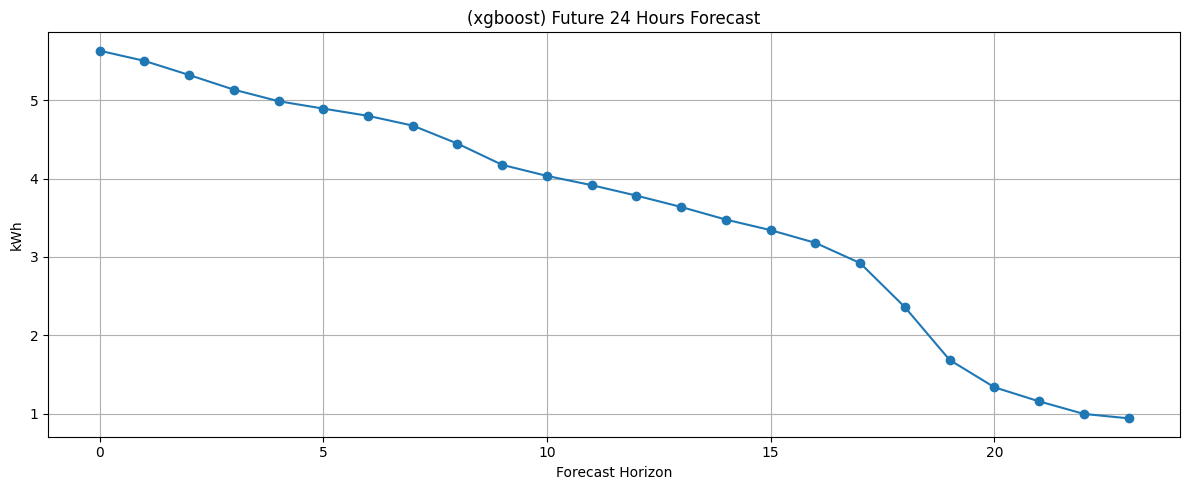

In [ ]:
plt.figure(figsize=(12,5))

plt.plot(
    range(24),
    future_24h["kwh_1h"],
    marker='o'
)

plt.title(
    '(xgboost) Future 24 Hours Forecast'
)

plt.xlabel('Forecast Horizon')
plt.ylabel('kWh')

plt.grid(True)

plt.tight_layout()

Connected to Python 3.12.10

In [ ]:
feature_scaler = joblib.load(
    "gru_v4_feature_scaler.pkl"
)

target_scaler = joblib.load(
    "gru_v4_target_scaler.pkl"
)

model = GRUModel(
    input_size=len(FEATURES),
    hidden_size=128,
    num_layers=2,
    output_size=24
).to(device)

model.load_state_dict(
    torch.load(
        "gru_v4_final.pth",
        map_location=device
    )
)

model.eval()

print("모델 로드 완료")

NameError: name 'joblib' is not defined

In [ ]:
import joblib

torch.save(
    final_model.state_dict(),
    "gru_v4_final.pth"
)

joblib.dump(
    feature_scaler,
    "gru_v4_feature_scaler.pkl"
)

joblib.dump(
    target_scaler,
    "gru_v4_target_scaler.pkl"
)

print("모델 저장 완료")

NameError: name 'torch' is not defined

In [ ]:
import joblib
import torch

feature_scaler = joblib.load(
    "gru_v4_feature_scaler.pkl"
)

target_scaler = joblib.load(
    "gru_v4_target_scaler.pkl"
)

model = GRUModel(
    input_size=len(FEATURES),
    hidden_size=128,
    num_layers=2,
    output_size=24
).to(device)

model.load_state_dict(
    torch.load(
        "gru_v4_final.pth",
        map_location=device
    )
)

model.eval()

print("모델 로드 완료")

NameError: name 'GRUModel' is not defined

In [ ]:
class GRUModel(nn.Module):

    def __init__(
        self,
        input_size,
        hidden_size=128,
        num_layers=2,
        output_size=24
    ):

        super().__init__()

        self.gru = nn.GRU(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True
        )

        self.fc = nn.Linear(
            hidden_size,
            output_size
        )

    def forward(self, x):

        out, hidden = self.gru(x)

        # 마지막 시점 Hidden State 사용
        out = out[:, -1, :]

        out = self.fc(out)

        return out

NameError: name 'nn' is not defined

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


import holidays

import joblib
import requests


from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error
)

from sklearn.metrics import (
    mean_absolute_error
)

from sklearn.preprocessing import (
    StandardScaler
)

import torch
import torch.nn as nn

from torch.utils.data import (
    Dataset,
    DataLoader
)

In [ ]:
import joblib
import torch

feature_scaler = joblib.load(
    "gru_v4_feature_scaler.pkl"
)

target_scaler = joblib.load(
    "gru_v4_target_scaler.pkl"
)

model = GRUModel(
    input_size=len(FEATURES),
    hidden_size=128,
    num_layers=2,
    output_size=24
).to(device)

model.load_state_dict(
    torch.load(
        "gru_v4_final.pth",
        map_location=device
    )
)

model.eval()

print("모델 로드 완료")

NameError: name 'GRUModel' is not defined

In [ ]:
# =====================================
# 🎉 energy planner project 🎉
# =====================================
#
# energy_planner_v4_predict.py
# 저장된 GRU 모델을 이용한
# 향후 24시간 전력 사용량 예측
#
# =====================================

#%% 🔥라이브러리

import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import joblib
import json

In [ ]:
class GRUModel(nn.Module):

    def __init__(
        self,
        input_size,
        hidden_size=128,
        num_layers=2,
        output_size=24
    ):

        super().__init__()

        self.gru = nn.GRU(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True
        )

        self.fc = nn.Linear(
            hidden_size,
            output_size
        )

    def forward(self, x):

        out, hidden = self.gru(x)

        out = out[:, -1, :]

        out = self.fc(out)

        return out

In [ ]:
with open(
    "feature_columns.json",
    "r"
) as f:

    FEATURES = json.load(f)

print(f"Feature 개수 : {len(FEATURES)}")

Feature 개수 : 26


In [ ]:
feature_scaler = joblib.load(
    "gru_v4_feature_scaler.pkl"
)

target_scaler = joblib.load(
    "gru_v4_target_scaler.pkl"
)

print("Scaler Load 완료")

Scaler Load 완료


In [ ]:
model = GRUModel(
    input_size=len(FEATURES),
    hidden_size=128,
    num_layers=2,
    output_size=24
)

In [ ]:
model.load_state_dict(
    torch.load(
        "gru_v4_final.pth",
        map_location="cpu"
    )
)

model.eval()

print("Model Load 완료")

Model Load 완료


In [ ]:
df = pd.read_csv(
    "df_hour_v4.csv"
)

print(df.shape)

(6075, 37)


In [ ]:
X_input = (
    df[FEATURES]
    .tail(168)
)

print(X_input.shape)

(168, 26)


In [ ]:
X_scaled = feature_scaler.transform(
    X_input
)

print(X_scaled.shape)

(168, 26)


In [ ]:
X_tensor = torch.tensor(
    X_scaled,
    dtype=torch.float32
).unsqueeze(0)

print(X_tensor.shape)

torch.Size([1, 168, 26])


In [ ]:
with torch.no_grad():

    pred_scaled = model(
        X_tensor
    ).numpy()

print(pred_scaled.shape)

(1, 24)


In [ ]:
pred = (
    target_scaler
    .inverse_transform(
        pred_scaled.reshape(-1, 1)
    )
    .flatten()
)

print(pred.shape)

(24,)


In [ ]:
pred_df = pd.DataFrame({

    "hour_ahead":
        range(1, 25),

    "pred_kwh":
        pred

})

print(pred_df)

    hour_ahead  pred_kwh
0            1  5.446555
1            2  4.494834
2            3  2.753081
3            4  1.788566
4            5  1.620964
5            6  1.541818
6            7  1.424331
7            8  1.514302
8            9  1.563848
9           10  1.469438
10          11  1.356228
11          12  1.277482
12          13  1.231250
13          14  1.278857
14          15  1.852301
15          16  3.224262
16          17  4.538494
17          18  5.265486
18          19  4.741081
19          20  4.423692
20          21  4.654113
21          22  5.012834
22          23  5.210250
23          24  5.013898


In [ ]:
pred_df.to_csv(
    "gru_v4_prediction.csv",
    index=False,
    encoding="utf-8-sig"
)

print(
    "\n예측 완료 : gru_v4_prediction.csv"
)


예측 완료 : gru_v4_prediction.csv


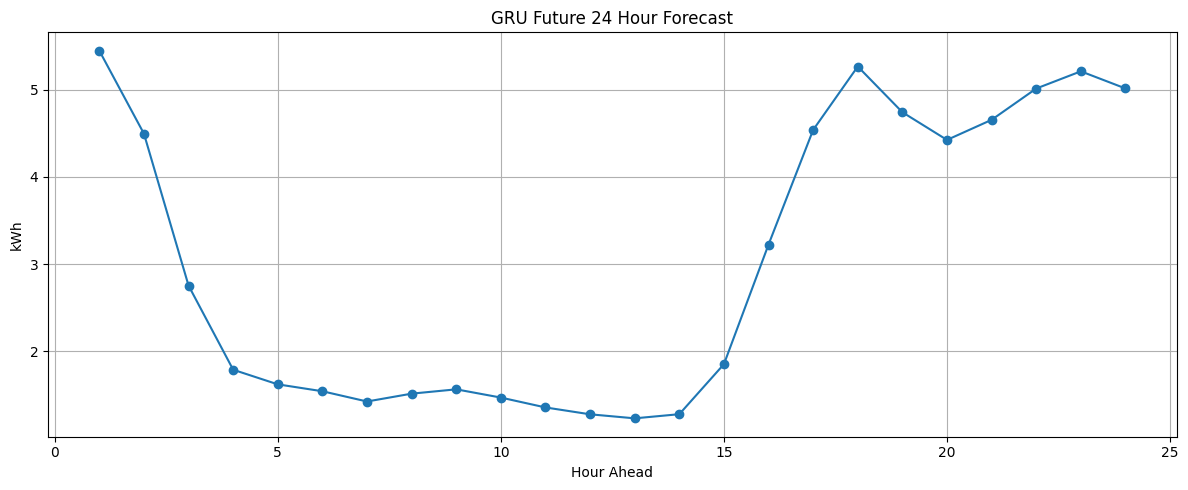

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

plt.plot(
    range(1,25),
    pred,
    marker='o'
)

plt.title(
    'GRU Future 24 Hour Forecast'
)

plt.xlabel('Hour Ahead')
plt.ylabel('kWh')

plt.grid(True)

plt.tight_layout()

plt.show()

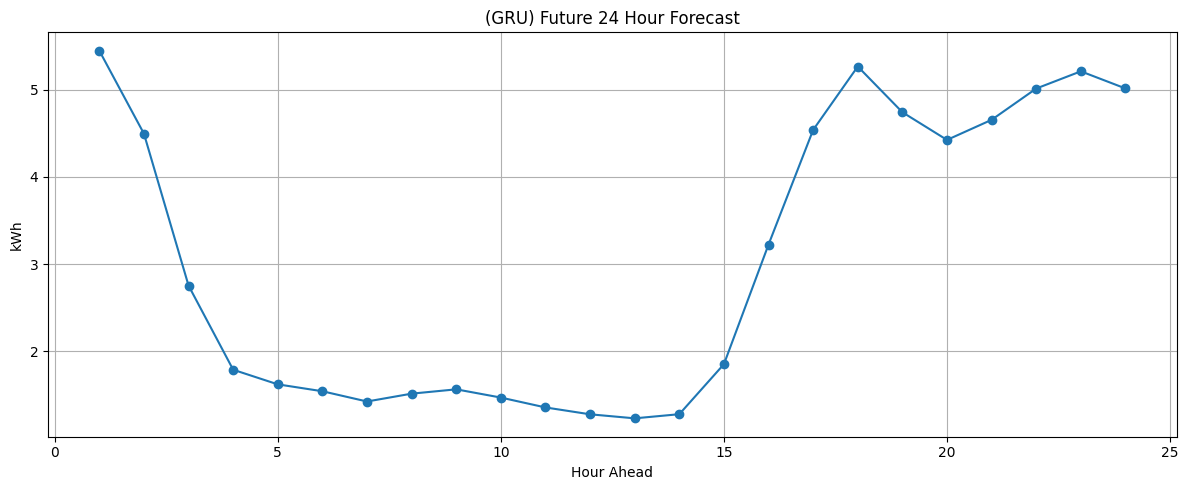

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

plt.plot(
    range(1,25),
    pred,
    marker='o'
)

plt.title(
    '(GRU) Future 24 Hour Forecast'
)

plt.xlabel('Hour Ahead')
plt.ylabel('kWh')

plt.grid(True)

plt.tight_layout()

plt.show()

In [ ]:
# =====================================
# 🎉 energy planner project 🎉
# =====================================
#
# energy_planner_v4.py
# GRU 기반 전력 사용량 예측 모델
# XGBoost Recursive Forecast의 오차 누적 문제를 개선하고
# 장기 시계열 패턴 학습 및 Multi-Step Forecast 성능 향상을 목적으로 개발
#

# [개발 환경 분리 안내]

# [v4 실행]
# venv312 활성화
# > venv312\Scripts\activate
# > python energy_planner_v4.py

# ============================================================

#%% 🔥라이브러리
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


import holidays

import joblib
import requests


from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error
)

from sklearn.metrics import (
    mean_absolute_error
)

from sklearn.preprocessing import (
    StandardScaler
)

import torch
import torch.nn as nn

from torch.utils.data import (
    Dataset,
    DataLoader
)

In [ ]:
# =====================================
# Data Preprocessing (전처리)
# =====================================

In [ ]:
df_p15d = pd.read_csv('power_15m_data_202605271649.csv')

# meter_id별 데이터 개수 확인
print(df_p15d['meter_id'].value_counts())

meter_id
1    733716
2     17370
Name: count, dtype: int64


In [ ]:
df_p15d = df_p15d[
    (df_p15d['meter_id'] == 1)
    &
    (df_p15d['channel_no'] == 1)
]

# 확인
print(df_p15d[['meter_id', 'channel_no']].value_counts())

meter_id  channel_no
1         1             26057
Name: count, dtype: int64


In [ ]:
print(df_p15d.isnull().sum())

meter_id                0
channel_no              0
ts                      0
current_power_kw        0
kwh_this_month          0
kwh_last_month          0
kwh_sum                 0
daily_kwh               0
bill_15m                0
demand_kw           12849
dtype: int64


In [ ]:
df_p15d = df_p15d.drop(
    ['demand_kw', 'bill_15m'],
    axis=1,
    errors='ignore'
)

In [ ]:
#print(df_p15d.iloc[0])

In [ ]:
#df_p15d = df_p15d.iloc[1:].reset_index(drop=True)

# ♻️수정>>> 초, 밀리초 제거 > 데이터를 날짜와 시간 순서로 정렬 > 완전히 날짜와 시간 같은 중복된 데이터 확인 > 중복된 데이터 삭제 

In [ ]:
# ts 컬럼 datetime 변환
df_p15d['ts'] = pd.to_datetime(df_p15d['ts'])

# 초 + 밀리초 제거
df_p15d['ts'] = df_p15d['ts'].dt.floor('min')

# ts 기준 시간순 정렬
df_p15d = df_p15d.sort_values('ts')

# ts 중복 제거 
df_p15d = (
    df_p15d
    .drop_duplicates(
        subset='ts',
        keep='last'
    )
)

# 인덱스 초기화
df_p15d = df_p15d.reset_index(drop=True)

# 확인
print(df_p15d['ts'].head(10))

0   2025-08-20 11:30:00+09:00
1   2025-08-20 11:45:00+09:00
2   2025-08-20 12:00:00+09:00
3   2025-08-20 12:15:00+09:00
4   2025-08-20 12:30:00+09:00
5   2025-08-20 12:45:00+09:00
6   2025-08-20 13:00:00+09:00
7   2025-08-20 13:15:00+09:00
8   2025-08-20 13:30:00+09:00
9   2025-08-20 13:45:00+09:00
Name: ts, dtype: datetime64[us, UTC+09:00]


In [ ]:
# 전체 15분 시계열 생성
full_ts = pd.date_range(
    start=df_p15d['ts'].min(),
    end=df_p15d['ts'].max(),
    freq='15min'
)

# 누락된 시간 추출
missing_ts = full_ts.difference(
    df_p15d['ts']
)

print(
    f'전체 누락 시간 개수 : {len(missing_ts)}'
)

# 월별 누락 개수 집계
missing_month = pd.DataFrame({
    'month': missing_ts.to_period('M').astype(str)
})

print("\n월별 누락 시간 개수")
print(
    missing_month['month']
    .value_counts()
    .sort_index()
)

# ♻️수정 >>> ts에서 빈 날짜, 빈 시간대 확인 

전체 누락 시간 개수 : 927

월별 누락 시간 개수
month
2025-08     19
2025-09    472
2025-10    143
2025-11      3
2025-12      8
2026-01    275
2026-03      6
2026-05      1
Name: count, dtype: int64


<ipython-input-10-7bd57c1fef0b>:21: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  'month': missing_ts.to_period('M').astype(str)


In [ ]:
# 누적 전력량(kwh_sum) → 15분 사용량

# 시간 간격(분) 계산
df_p15d['time_diff'] = (
    df_p15d['ts']
    .diff()
    .dt.total_seconds()
    / 60
)

# 15분 간격일 때만 사용량 계산
df_p15d['kwh_15m'] = np.where(
    df_p15d['time_diff'] == 15,
    df_p15d['kwh_sum'].diff(),
    np.nan
)

# 계산 불가능 구간 제거
df_p15d = (
    df_p15d
    .dropna(subset=['kwh_15m'])
    .reset_index(drop=True)
)

# 확인
print(
    df_p15d[
        ['ts', 'time_diff', 'kwh_sum', 'kwh_15m']
    ].head()
)

                         ts  time_diff  kwh_sum  kwh_15m
0 2025-08-20 11:45:00+09:00       15.0    135.7      1.4
1 2025-08-20 12:00:00+09:00       15.0    137.0      1.3
2 2025-08-20 12:15:00+09:00       15.0    137.9      0.9
3 2025-08-20 12:30:00+09:00       15.0    138.7      0.8
4 2025-08-20 12:45:00+09:00       15.0    139.5      0.8


In [ ]:
# ts를 인덱스로 설정
df_hour = (
    df_p15d
    .set_index('ts')
    .resample('1h')
    .agg(
        kwh_1h=('kwh_15m', 'sum'),
        cnt=('kwh_15m', 'count')
    )
    .reset_index()
)

# 15분 데이터가 4개 모두 존재하는 시간만 사용
df_hour = df_hour[
    df_hour['cnt'] == 4
]

# (선택) 이후 feature 생성 시 cnt는 필요 없으므로 제거
df_hour = df_hour.drop(columns='cnt')

# 확인
print(df_hour.head())
print(df_hour.shape)

                         ts  kwh_1h
1 2025-08-20 12:00:00+09:00     3.8
2 2025-08-20 13:00:00+09:00     5.0
3 2025-08-20 14:00:00+09:00     5.2
4 2025-08-20 15:00:00+09:00     5.2
5 2025-08-20 16:00:00+09:00     5.1
(6435, 2)


In [ ]:
# 전체 기간(15분 간격) 생성
full_ts = pd.date_range(
    start=df_p15d['ts'].min(),
    end=df_p15d['ts'].max(),
    freq='15min'
)

# 실제 ts와 비교하여 누락된 시간 찾기
missing_ts = full_ts.difference(
    df_p15d['ts']
)

# 결과 출력
print(
    f'누락된 시간 개수 : {len(missing_ts)}'
)

if len(missing_ts) > 0:

    # 월(month) 컬럼 생성
    missing_df = pd.DataFrame({
        'month': missing_ts.to_period('M').astype(str)
    })

    print('\n월별 누락 시간 개수')

    print(
        missing_df['month']
        .value_counts()
        .sort_index()
    )

else:
    print('\n누락된 날짜 및 시간이 없습니다.')

누락된 시간 개수 : 988

월별 누락 시간 개수
month
2025-08     26
2025-09    498
2025-10    151
2025-11      6
2025-12     10
2026-01    288
2026-03      7
2026-05      2
Name: count, dtype: int64


<ipython-input-13-6a2c27442358>:24: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  'month': missing_ts.to_period('M').astype(str)


In [ ]:
full_hour = pd.date_range(
    start=df_hour['ts'].min(),
    end=df_hour['ts'].max(),
    freq='1h'
)

missing_hour = full_hour.difference(
    df_hour['ts']
)

print(
    f'1시간 단위 누락 개수 : {len(missing_hour)}'
)

1시간 단위 누락 개수 : 290


In [ ]:
# 누락된 시간대가 많은 달은 예측의 오차 발생 가능
# month
# 2025-09    144
# 2026-01     82
# 2025-10     42

# missing_hour : 누락된 1시간 datetime Index

missing_month = pd.DataFrame({
    'month': missing_hour.to_period('M').astype(str)
})

monthly_missing = (
    missing_month['month']
    .value_counts()          # 월별 누락 시간 개수
    .sort_values(ascending=False)   # 내림차순 정렬
)

print(monthly_missing)

month
2025-09    144
2026-01     82
2025-10     42
2025-08     10
2025-11      4
2025-12      4
2026-03      3
2026-05      1
Name: count, dtype: int64


<ipython-input-15-578ed2da7aaa>:11: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  'month': missing_hour.to_period('M').astype(str)


In [ ]:
# 하순(21~31일)    57
# 상순(1~10일)     16
# 중순(11~20일)     9

# missing_hour : 누락된 1시간 datetime Index

# DataFrame 생성
jan_missing = pd.DataFrame({
    'missing_ts': missing_hour
})

# 1월 데이터만 추출
jan_missing = jan_missing[
    jan_missing['missing_ts'].dt.month == 1
].copy()

# 일(day) 컬럼 생성
jan_missing['day'] = jan_missing['missing_ts'].dt.day

# 날짜별 누락 시간 개수
jan_dist = (
    jan_missing['day']
    .value_counts()
    .sort_index()
)

print("1월 날짜별 누락 시간 개수")
print(jan_dist)


# 상순 / 중순 / 하순 집계
# -------------------------------
jan_missing['period'] = np.where(
    jan_missing['day'] <= 10,
    '상순(1~10일)',
    np.where(
        jan_missing['day'] <= 20,
        '중순(11~20일)',
        '하순(21~31일)'
    )
)

print("\n1월 상·중·하순별 누락 시간 개수")
print(
    jan_missing['period']
    .value_counts()
)

1월 날짜별 누락 시간 개수
day
5      2
6      4
9     10
15     1
16     4
19     3
20     1
21     1
27    14
28    24
29    18
Name: count, dtype: int64

1월 상·중·하순별 누락 시간 개수
period
하순(21~31일)    57
상순(1~10일)     16
중순(11~20일)     9
Name: count, dtype: int64


In [ ]:
df_p15d.to_csv(
    'df_p15d.csv',
    index=False,
    encoding='utf-8-sig'
)

In [ ]:
# =====================================
# feature engineering
# =====================================

In [ ]:
# ts 컬럼에서 시간(hour) 추출 → 0~23 시간대 변수 생성

df_hour['hour'] = df_hour['ts'].dt.hour

# 확인
print(df_hour[['ts', 'hour']].head())

                         ts  hour
1 2025-08-20 12:00:00+09:00    12
2 2025-08-20 13:00:00+09:00    13
3 2025-08-20 14:00:00+09:00    14
4 2025-08-20 15:00:00+09:00    15
5 2025-08-20 16:00:00+09:00    16


In [ ]:
# ts 컬럼에서 요일(weekday) 추출
# Monday=0, Sunday=6 형태로 생성됨

df_hour['weekday'] = df_hour['ts'].dt.weekday

# 확인
print(df_hour[['ts', 'weekday']].head())

                         ts  weekday
1 2025-08-20 12:00:00+09:00        2
2 2025-08-20 13:00:00+09:00        2
3 2025-08-20 14:00:00+09:00        2
4 2025-08-20 15:00:00+09:00        2
5 2025-08-20 16:00:00+09:00        2


In [ ]:
# weekday를 기준으로 주말 여부 생성
# Saturday(5), Sunday(6) = 1 (주말), 그 외 = 0 (평일)

df_hour['is_weekend'] = (
    df_hour['weekday'].isin([5, 6])
).astype(int)

# 확인
print(
    df_hour[
        ['ts', 'weekday', 'is_weekend']
    ].head()
)

                         ts  weekday  is_weekend
1 2025-08-20 12:00:00+09:00        2           0
2 2025-08-20 13:00:00+09:00        2           0
3 2025-08-20 14:00:00+09:00        2           0
4 2025-08-20 15:00:00+09:00        2           0
5 2025-08-20 16:00:00+09:00        2           0


In [ ]:
# holidays.KR() : 한국 법정 공휴일 자동 제공

is_holiday = set(holidays.KR().keys())

# 노동절(5월 1일) 추가
labor_day = pd.to_datetime(
    ["2026-05-01"]
).date

# date 컬럼 생성 (없으면 추가)
df_hour['date'] = df_hour['ts'].dt.date

# 공휴일 여부 생성
df_hour['is_holiday'] = (
    df_hour['date'].isin(is_holiday)
    |
    df_hour['date'].isin(labor_day)
).astype(int)

# 확인
print(
    df_hour[
        ['ts', 'is_holiday']
    ].head()
)

                         ts  is_holiday
1 2025-08-20 12:00:00+09:00           0
2 2025-08-20 13:00:00+09:00           0
3 2025-08-20 14:00:00+09:00           0
4 2025-08-20 15:00:00+09:00           0
5 2025-08-20 16:00:00+09:00           0


In [ ]:
# ts 컬럼에서 월(month) 추출

df_hour['month'] = df_hour['ts'].dt.month

# 확인
print(df_hour[['ts', 'month']].head())

                         ts  month
1 2025-08-20 12:00:00+09:00      8
2 2025-08-20 13:00:00+09:00      8
3 2025-08-20 14:00:00+09:00      8
4 2025-08-20 15:00:00+09:00      8
5 2025-08-20 16:00:00+09:00      8


In [ ]:
# ts 컬럼에서 일(day) 추출

df_hour['day'] = df_hour['ts'].dt.day

# 확인
print(df_hour[['ts', 'day']].head())

                         ts  day
1 2025-08-20 12:00:00+09:00   20
2 2025-08-20 13:00:00+09:00   20
3 2025-08-20 14:00:00+09:00   20
4 2025-08-20 15:00:00+09:00   20
5 2025-08-20 16:00:00+09:00   20


In [ ]:
# df_hour(전력 사용량)과 df_temp(기온 데이터)를 안정적으로 결합하여 
# 온도 Feature를 생성하기 위한 전처리 과정

df_temp = pd.read_csv("gwangju_temp.csv")

# 전부 NaN 행 제거
df_temp = df_temp.dropna(how='all')

# date 문자열 정리
df_temp['date'] = df_temp['date'].astype(str).str.strip()

# datetime 변환 (안전 처리)
df_temp['date'] = pd.to_datetime(df_temp['date'], errors='coerce')

# NaT 제거
df_temp = df_temp.dropna(subset=['date'])

# 중복 제거 (중요)
df_temp = df_temp.drop_duplicates(subset=['date'])

# 날짜만 남기기 (timezone 제거 + key 통일)
df_temp['date'] = df_temp['date'].dt.floor('D').dt.date

In [ ]:
df_hour['ts'] = pd.to_datetime(df_hour['ts'])

df_hour['date'] = df_hour['ts'].dt.date

In [ ]:
df_hour = pd.merge(
    df_hour,
    df_temp,
    on='date',
    how='left'
)

In [ ]:
print("temp 결측 비율:", df_hour['avg_temp'].isna().mean())

temp 결측 비율: 0.0


In [ ]:
print(df_hour.columns)

Index(['ts', 'kwh_1h', 'hour', 'weekday', 'is_weekend', 'date', 'is_holiday',
       'month', 'day', 'avg_temp', 'daily_min_temp', 'daily_max_temp'],
      dtype='str')


In [ ]:
# 컬럼명 공백 제거
df_hour.columns = df_hour.columns.str.strip()

# --------------------------
# 1. ✨temp_range
# 일교차 (max - min)
df_hour['temp_range'] = (
    df_hour['daily_max_temp']
    - df_hour['daily_min_temp']
)


# --------------------------
# 2. ✨temp_centered
# 최근 7일 평균 대비 현재 기온 편차
# 7일 = 24 * 7 = 168시간
df_hour['temp_centered'] = (
    df_hour['avg_temp']
    - df_hour['avg_temp']
        .rolling(window=168, min_periods=1)
        .mean()
)


# --------------------------
# 3. ✨temp_ma_24 ✨temp_ma_168
# 1일 / 7일 이동평균
df_hour['temp_ma_24'] = (
    df_hour['avg_temp']
        .rolling(window=24, min_periods=1)
        .mean()
)

df_hour['temp_ma_168'] = (
    df_hour['avg_temp']
        .rolling(window=168, min_periods=1)
        .mean()
)


# --------------------------
# 4. ✨temp_diff_24 ✨temp_diff_168
# 1일 전 / 7일 전 대비 기온 변화
df_hour['temp_diff_24'] = (
    df_hour['avg_temp'].diff(24)
)

df_hour['temp_diff_168'] = (
    df_hour['avg_temp'].diff(168)
)


# --------------------------
# 5. ✨ Temperature Indicator

# 더운 날
df_hour['is_hot'] = (
    df_hour['avg_temp'] >= 28
).astype(int)

# 추운 날
df_hour['is_cold'] = (
    df_hour['avg_temp'] <= 5
).astype(int)

# 강한 추위
df_hour['is_very_cold'] = (
    df_hour['avg_temp'] <= 0
).astype(int)

# 극한 추위 (광주에서는 드문 이벤트)
df_hour['is_extreme_cold'] = (
    df_hour['avg_temp'] <= -3
).astype(int)

# 전일 대비 평균기온 변화량
df_hour['temp_diff_prev_day'] = (
    df_hour['avg_temp']
    - df_hour['avg_temp'].shift(24)
)

# 전일 대비 평균기온 5℃ 이상 하락
df_hour['is_temp_drop_5'] = (
    df_hour['temp_diff_prev_day'] <= -5
).astype(int)


# --------------------------
# 6. ✨cooling_degree ✨heating_degree
# 냉방/난방 필요도
df_hour['cooling_degree'] = (
    df_hour['avg_temp'] - 24
).clip(lower=0)

df_hour['heating_degree'] = (
    18 - df_hour['avg_temp']
).clip(lower=0)


# 확인
print(
    df_hour[
        [
            'ts',
            'avg_temp',
            'temp_range',
            'temp_centered',
            'temp_ma_24',
            'temp_ma_168',
            'temp_diff_24',
            'temp_diff_168'
        ]
    ].head()
)

                         ts  avg_temp  temp_range  temp_centered  temp_ma_24  \
0 2025-08-20 12:00:00+09:00      28.7         9.3            0.0        28.7   
1 2025-08-20 13:00:00+09:00      28.7         9.3            0.0        28.7   
2 2025-08-20 14:00:00+09:00      28.7         9.3            0.0        28.7   
3 2025-08-20 15:00:00+09:00      28.7         9.3            0.0        28.7   
4 2025-08-20 16:00:00+09:00      28.7         9.3            0.0        28.7   

   temp_ma_168  temp_diff_24  temp_diff_168  
0         28.7           NaN            NaN  
1         28.7           NaN            NaN  
2         28.7           NaN            NaN  
3         28.7           NaN            NaN  
4         28.7           NaN            NaN  


In [ ]:
# --------------------------
# 1시간 단위 예측용 Lag Feature

# 1시간 전
df_hour['lag_1'] = df_hour['kwh_1h'].shift(1)

# 1일 전 같은 시간
df_hour['lag_24'] = df_hour['kwh_1h'].shift(24)

# 1주일 전 같은 시간
df_hour['lag_168'] = df_hour['kwh_1h'].shift(168)

# --------------------------
# 결측 처리
# 가장 긴 lag(168) 기준 제거

df_hour = df_hour.iloc[168:].reset_index(drop=True)

# 확인
print(
    df_hour[
        ['ts', 'kwh_1h', 'lag_1', 'lag_24', 'lag_168']
    ].head()
)

                         ts  kwh_1h  lag_1  lag_24  lag_168
0 2025-08-27 22:00:00+09:00     0.9    0.7     1.4      3.8
1 2025-08-27 23:00:00+09:00     0.9    0.9     1.3      5.0
2 2025-08-28 00:00:00+09:00     0.8    0.9     1.4      5.2
3 2025-08-28 01:00:00+09:00     0.8    0.8     1.5      5.2
4 2025-08-28 02:00:00+09:00     0.7    0.8     1.3      5.1


In [ ]:
# --------------------------
# Rolling Feature 생성

# 최근 3시간 평균
df_hour['rolling_mean_3'] = (
    df_hour['kwh_1h']
    .rolling(window=3)
    .mean()
)

# 최근 6시간 평균
df_hour['rolling_mean_6'] = (
    df_hour['kwh_1h']
    .rolling(window=6)
    .mean()
)

# 최근 24시간 평균
df_hour['rolling_mean_24'] = (
    df_hour['kwh_1h']
    .rolling(window=24)
    .mean()
)

# 최근 24시간 최대값
df_hour['rolling_max_24'] = (
    df_hour['kwh_1h']
    .rolling(window=24)
    .max()
)

# 최근 24시간 최소값
df_hour['rolling_min_24'] = (
    df_hour['kwh_1h']
    .rolling(window=24)
    .min()
)

# --------------------------
# 결측 처리
# 가장 긴 rolling window(24) 기준 제거

df_hour = df_hour.iloc[24:].reset_index(drop=True)

# 확인
print(
    df_hour[
        [
            'ts',
            'kwh_1h',
            'rolling_mean_3',
            'rolling_mean_6',
            'rolling_mean_24'
        ]
    ].head()
)

                         ts  kwh_1h  rolling_mean_3  rolling_mean_6  \
0 2025-08-28 22:00:00+09:00     1.4        1.500000        2.566667   
1 2025-08-28 23:00:00+09:00     1.5        1.500000        1.866667   
2 2025-08-29 00:00:00+09:00     1.4        1.433333        1.466667   
3 2025-08-29 01:00:00+09:00     1.5        1.466667        1.483333   
4 2025-08-29 02:00:00+09:00     1.4        1.433333        1.466667   

   rolling_mean_24  
0         3.004167  
1         3.029167  
2         3.054167  
3         3.083333  
4         3.112500  


In [ ]:
# --------------------------
# Difference Feature 생성 (kwh_1h 기준)

# 직전 1시간 대비 변화량
df_hour['diff_1'] = df_hour['kwh_1h'].diff(1)

# 1일 전 동일 시간 대비 변화량
df_hour['diff_24'] = df_hour['kwh_1h'].diff(24)

# 1주일 전 동일 시간 대비 변화량
df_hour['diff_168'] = df_hour['kwh_1h'].diff(168)

# --------------------------
# 결측 처리
# 가장 큰 diff 기준(168) 이후 데이터 사용

df_hour = df_hour.iloc[168:].reset_index(drop=True)

# 확인
print(
    df_hour[
        [
            'ts',
            'kwh_1h',
            'diff_1',
            'diff_24',
            'diff_168'
        ]
    ].head()
)



# 더운 날
df_hour['is_hot'] = (
    df_hour['avg_temp'] >= 28
).astype(int)

# 추운 날
df_hour['is_cold'] = (
    df_hour['avg_temp'] <= 5
).astype(int)

# 강한 추위
df_hour['is_very_cold'] = (
    df_hour['avg_temp'] <= 0
).astype(int)

# 극한 추위 (광주에서는 드문 이벤트)
df_hour['is_extreme_cold'] = (
    df_hour['avg_temp'] <= -3
).astype(int)


# --------------------------
# 6. ✨cooling_degree ✨heating_degree
# 냉방/난방 필요도
df_hour['cooling_degree'] = (
    df_hour['avg_temp'] - 24
).clip(lower=0)

df_hour['heating_degree'] = (
    18 - df_hour['avg_temp']
).clip(lower=0)


# 확인
print(
    df_hour[
        [
            'ts',
            'avg_temp',
            'temp_range',
            'cooling_degree',
            'heating_degree'
        ]
    ].head()
)

                         ts  kwh_1h        diff_1  diff_24  diff_168
0 2025-09-06 10:00:00+09:00     1.3  2.273737e-13     -0.2      -0.1
1 2025-09-06 11:00:00+09:00     1.3 -2.273737e-13     -0.3      -0.2
2 2025-09-06 12:00:00+09:00     1.2 -1.000000e-01     -0.3      -0.2
3 2025-09-06 13:00:00+09:00     1.2 -2.273737e-13     -0.2      -0.3
4 2025-09-06 14:00:00+09:00     1.5  3.000000e-01      0.1       0.1
                         ts  avg_temp  temp_range  cooling_degree  \
0 2025-09-06 10:00:00+09:00      28.3         7.5             4.3   
1 2025-09-06 11:00:00+09:00      28.3         7.5             4.3   
2 2025-09-06 12:00:00+09:00      28.3         7.5             4.3   
3 2025-09-06 13:00:00+09:00      28.3         7.5             4.3   
4 2025-09-06 14:00:00+09:00      28.3         7.5             4.3   

   heating_degree  
0             0.0  
1             0.0  
2             0.0  
3             0.0  
4             0.0  


In [ ]:
# 동일 feature set 비교를 위해 보류
#df_hour['hour_sin'] = np.sin(
#    2 * np.pi * df_hour['hour'] / 24
#)

#df_hour['hour_cos'] = np.cos(
#    2 * np.pi * df_hour['hour'] / 24
#)

#df_hour['weekday_sin'] = np.sin(
#    2 * np.pi * df_hour['weekday'] / 7
#)

#df_hour['weekday_cos'] = np.cos(
#    2 * np.pi * df_hour['weekday'] / 7
#)

In [ ]:
df_hour.to_csv(
    'df_hour_v4.csv',
    index=False,
    encoding='utf-8-sig'
)
print(df_hour.shape)
print(df_hour.columns)
print("저장 완료 : df_hour_v4.csv")

(6075, 37)
Index(['ts', 'kwh_1h', 'hour', 'weekday', 'is_weekend', 'date', 'is_holiday',
       'month', 'day', 'avg_temp', 'daily_min_temp', 'daily_max_temp',
       'temp_range', 'temp_centered', 'temp_ma_24', 'temp_ma_168',
       'temp_diff_24', 'temp_diff_168', 'is_hot', 'is_cold', 'is_very_cold',
       'is_extreme_cold', 'temp_diff_prev_day', 'is_temp_drop_5',
       'cooling_degree', 'heating_degree', 'lag_1', 'lag_24', 'lag_168',
       'rolling_mean_3', 'rolling_mean_6', 'rolling_mean_24', 'rolling_max_24',
       'rolling_min_24', 'diff_1', 'diff_24', 'diff_168'],
      dtype='str')
저장 완료 : df_hour_v4.csv

Index(['ts', 'kwh_1h', 'hour', 'weekday', 'is_weekend', 'date', 'is_holiday',
       'month', 'day', 'avg_temp', 'daily_min_temp', 'daily_max_temp',
       'temp_range', 'temp_centered', 'temp_ma_24', 'temp_ma_168',
       'temp_diff_24', 'temp_diff_168', 'is_hot', 'is_cold', 'is_very_cold',
       'is_extreme_cold', 'temp_diff_prev_day', 'is_temp_drop_5',
       'cooling_

In [ ]:
# =====================================
# Feature Selection
# =====================================

In [ ]:
import json

with open("feature_columns.json", "r") as f:
    FEATURES = json.load(f)

print(f"Feature 개수: {len(FEATURES)}")

TARGET = 'kwh_1h'

Feature 개수: 26


In [ ]:
df_hour = df_hour.dropna().reset_index(drop=True)

print(df_hour.shape)

(6075, 37)


In [ ]:
# =====================================
# Sequence Dataset 생성
# =====================================

In [ ]:
def create_sequence(
    X,
    y,
    lookback=168,
    horizon=24
):

    X_seq = []
    y_seq = []

    for i in range(
        lookback,
        len(X) - horizon
    ):

        X_seq.append(
            X[i-lookback:i]
        )

        y_seq.append(
            y[i:i+horizon, 0]
        )

    return (
        np.array(X_seq),
        np.array(y_seq)
    )

In [ ]:
class PowerDataset(Dataset):

    def __init__(
        self,
        X,
        y
    ):
        self.X = torch.tensor(
            X,
            dtype=torch.float32
        )

        self.y = torch.tensor(
            y,
            dtype=torch.float32
        )

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):

        return (
            self.X[idx],
            self.y[idx]
        )    

In [ ]:
device = torch.device(
    'cuda'
    if torch.cuda.is_available()
    else 'cpu'
)

print("Device :", device)

Device : cpu


In [ ]:
class GRUModel(nn.Module):

    def __init__(
        self,
        input_size,
        hidden_size=128,
        num_layers=2,
        output_size=24
    ):

        super().__init__()

        self.gru = nn.GRU(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True
        )

        self.fc = nn.Linear(
            hidden_size,
            output_size
        )

    def forward(self, x):

        out, hidden = self.gru(x)

        # 마지막 시점 Hidden State 사용
        out = out[:, -1, :]

        out = self.fc(out)

        return out

In [ ]:
# =====================================
# Walk-Forward Validation
# =====================================

In [ ]:
VALID_MONTHS = [
    '2025-11',
    '2025-12',
    '2026-01',
    '2026-02',
    '2026-03',
    '2026-04'
]

In [ ]:
results = []

fold_predictions = {}

In [ ]:
for fold, valid_month in enumerate(
    VALID_MONTHS,
    start=1
):

    print(
        f'\n========== Fold {fold} =========='
    )

    print(
        f'Validation : {valid_month}'
    )


    # Train / Valid 분리
    valid_mask = (
        df_hour['ts']
        .dt.to_period('M')
        .astype(str)
        == valid_month
    )

    valid_df = df_hour[
        valid_mask
    ].copy()

    valid_start = valid_df['ts'].min()

    train_df = df_hour[
        df_hour['ts'] < valid_start
    ].copy()

    valid_df_extended = pd.concat(
        [
            train_df.tail(168),
            valid_df
        ]
    ).reset_index(drop=True)

    

    # scaling
    feature_scaler = StandardScaler()
    target_scaler = StandardScaler()

    X_train_scaled = feature_scaler.fit_transform(
        train_df[FEATURES]
    )

    y_train_scaled = target_scaler.fit_transform(
        train_df[[TARGET]]
    )

    X_valid_scaled = feature_scaler.transform(
        valid_df_extended[FEATURES]
    )

    y_valid_scaled = target_scaler.transform(
        valid_df_extended[[TARGET]]
    )

    X_train_seq, y_train_seq = create_sequence(
        X_train_scaled,
        y_train_scaled
    )

    X_valid_seq, y_valid_seq = create_sequence(
        X_valid_scaled,
        y_valid_scaled
    )

    print(X_train_seq.shape)
    print(y_train_seq.shape)

    print(X_valid_seq.shape)
    print(y_valid_seq.shape)

    #🔥Fold Dataset 생성

    train_dataset = PowerDataset(
        X_train_seq,
        y_train_seq
    )

    valid_dataset = PowerDataset(
        X_valid_seq,
        y_valid_seq
    )
    #🔥Fold DataLoader 생성

    train_loader = DataLoader(
        train_dataset,
        batch_size=64,
        shuffle=False
    )

    valid_loader = DataLoader(
        valid_dataset,
        batch_size=64,
        shuffle=False
    )
    #🔥Fold Model 생성

    model = GRUModel(
        input_size=len(FEATURES),
        hidden_size=128,
        num_layers=2,
        output_size=24
    )

    model = model.to(device)
    #🔥Fold Loss / Optimizer

    criterion = nn.L1Loss()

    optimizer = torch.optim.Adam(

        model.parameters(),
        lr=0.001
    )
    
   
    #🚀Fold Training

    EPOCHS = 30

    for epoch in range(EPOCHS):

        model.train()

        train_loss = 0

        for X_batch, y_batch in train_loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            optimizer.zero_grad()

            pred = model(X_batch)

            loss = criterion(
                pred,
                y_batch
            )

            loss.backward()

            optimizer.step()

            train_loss += loss.item()

        train_loss /= len(train_loader)

        print(
            f'Fold {fold} | '
            f'Epoch {epoch+1}/{EPOCHS} | '
            f'Loss {train_loss:.4f}'
        )

    #🔥Fold Validation

    model.eval()

    preds = []
    trues = []

    with torch.no_grad():

        for X_batch, y_batch in valid_loader:

            X_batch = X_batch.to(device)

            pred = model(X_batch)

            preds.append(
                pred.cpu().numpy()
            )

            trues.append(
                y_batch.numpy()
            )

    #🔥Fold Inverse Scaling

    preds = np.concatenate(preds)
    trues = np.concatenate(trues)

    preds_inv = target_scaler.inverse_transform(
        preds.reshape(-1, 1)
    ).reshape(preds.shape)

    trues_inv = target_scaler.inverse_transform(
        trues.reshape(-1, 1)
    ).reshape(trues.shape)

    fold_predictions[valid_month] = {
            'preds': preds_inv.copy(),
            'trues': trues_inv.copy()
        } 

    #🔥Peak Metric

    peak_true = trues_inv.max(axis=1)
    peak_pred = preds_inv.max(axis=1)

    peak_mae = np.mean(
        np.abs(peak_true - peak_pred)
    )

    peak_hour_true = np.argmax(
        trues_inv,
        axis=1
    )

    peak_hour_pred = np.argmax(
        preds_inv,
        axis=1
    )

    peak_time_mae = np.mean(
        np.abs(
            peak_hour_true -
            peak_hour_pred
        )
    )

    #🔥Fold Metric

    mae = mean_absolute_error(
        trues_inv.flatten(),
        preds_inv.flatten()
    )

    rmse = np.sqrt(
        mean_squared_error(
            trues_inv.flatten(),
            preds_inv.flatten()
        )
    )

    mape = (
        mean_absolute_percentage_error(
            trues_inv.flatten(),
            preds_inv.flatten()
        ) * 100
    )

    print(
        f'Fold {fold} '
        f'MAE={mae:.4f} '
        f'RMSE={rmse:.4f} '
        f'MAPE={mape:.2f}%'
    )

    results.append({
        'fold': fold,
        'valid_month': valid_month,
        'mae': mae,
        'rmse': rmse,
        'mape': mape,
        'peak_mae': peak_mae,
        'peak_time_mae': peak_time_mae
    })


========== Fold 1 ==========
Validation : 2025-11
(992, 168, 26)
(992, 24)
(692, 168, 26)
(692, 24)


<ipython-input-47-bd799b017cf1>:20: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  .dt.to_period('M')


Fold 1 | Epoch 1/30 | Loss 0.8145
Fold 1 | Epoch 2/30 | Loss 0.6394
Fold 1 | Epoch 3/30 | Loss 0.5577
Fold 1 | Epoch 4/30 | Loss 0.5165
Fold 1 | Epoch 5/30 | Loss 0.5086
Fold 1 | Epoch 6/30 | Loss 0.4770
Fold 1 | Epoch 7/30 | Loss 0.4798
Fold 1 | Epoch 8/30 | Loss 0.4528
Fold 1 | Epoch 9/30 | Loss 0.4636
Fold 1 | Epoch 10/30 | Loss 0.4344
Fold 1 | Epoch 11/30 | Loss 0.4431
Fold 1 | Epoch 12/30 | Loss 0.4217
Fold 1 | Epoch 13/30 | Loss 0.4337
Fold 1 | Epoch 14/30 | Loss 0.3922
Fold 1 | Epoch 15/30 | Loss 0.4339
Fold 1 | Epoch 16/30 | Loss 0.3881
Fold 1 | Epoch 17/30 | Loss 0.3898
Fold 1 | Epoch 18/30 | Loss 0.3481
Fold 1 | Epoch 19/30 | Loss 0.3675
Fold 1 | Epoch 20/30 | Loss 0.3429
Fold 1 | Epoch 21/30 | Loss 0.3591
Fold 1 | Epoch 22/30 | Loss 0.3336
Fold 1 | Epoch 23/30 | Loss 0.3772
Fold 1 | Epoch 24/30 | Loss 0.3680
Fold 1 | Epoch 25/30 | Loss 0.3554
Fold 1 | Epoch 26/30 | Loss 0.3601
Fold 1 | Epoch 27/30 | Loss 0.3448
Fold 1 | Epoch 28/30 | Loss 0.3303
Fold 1 | Epoch 29/30 | Loss 0

<ipython-input-47-bd799b017cf1>:20: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  .dt.to_period('M')


Fold 2 | Epoch 1/30 | Loss 0.7581
Fold 2 | Epoch 2/30 | Loss 0.6219
Fold 2 | Epoch 3/30 | Loss 0.5322
Fold 2 | Epoch 4/30 | Loss 0.4910
Fold 2 | Epoch 5/30 | Loss 0.4624
Fold 2 | Epoch 6/30 | Loss 0.4397
Fold 2 | Epoch 7/30 | Loss 0.4079
Fold 2 | Epoch 8/30 | Loss 0.4720
Fold 2 | Epoch 9/30 | Loss 0.4583
Fold 2 | Epoch 10/30 | Loss 0.4111
Fold 2 | Epoch 11/30 | Loss 0.3753
Fold 2 | Epoch 12/30 | Loss 0.3429
Fold 2 | Epoch 13/30 | Loss 0.3335
Fold 2 | Epoch 14/30 | Loss 0.3378
Fold 2 | Epoch 15/30 | Loss 0.3359
Fold 2 | Epoch 16/30 | Loss 0.3594
Fold 2 | Epoch 17/30 | Loss 0.3383
Fold 2 | Epoch 18/30 | Loss 0.3240
Fold 2 | Epoch 19/30 | Loss 0.2919
Fold 2 | Epoch 20/30 | Loss 0.2945
Fold 2 | Epoch 21/30 | Loss 0.2992
Fold 2 | Epoch 22/30 | Loss 0.2856
Fold 2 | Epoch 23/30 | Loss 0.2792
Fold 2 | Epoch 24/30 | Loss 0.2794
Fold 2 | Epoch 25/30 | Loss 0.2857
Fold 2 | Epoch 26/30 | Loss 0.2744
Fold 2 | Epoch 27/30 | Loss 0.2690
Fold 2 | Epoch 28/30 | Loss 0.2727
Fold 2 | Epoch 29/30 | Loss 0

<ipython-input-47-bd799b017cf1>:20: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  .dt.to_period('M')


... (3 outputs left out)

<ipython-input-47-bd799b017cf1>:20: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  .dt.to_period('M')


Fold 5 | Epoch 1/30 | Loss 0.6947
Fold 5 | Epoch 2/30 | Loss 0.5506
Fold 5 | Epoch 3/30 | Loss 0.4997
Fold 5 | Epoch 4/30 | Loss 0.4678
Fold 5 | Epoch 5/30 | Loss 0.4498
Fold 5 | Epoch 6/30 | Loss 0.4429
Fold 5 | Epoch 7/30 | Loss 0.4199
Fold 5 | Epoch 8/30 | Loss 0.4088
Fold 5 | Epoch 9/30 | Loss 0.3991
Fold 5 | Epoch 10/30 | Loss 0.3952
Fold 5 | Epoch 11/30 | Loss 0.4091
Fold 5 | Epoch 12/30 | Loss 0.3987
Fold 5 | Epoch 13/30 | Loss 0.3580
Fold 5 | Epoch 14/30 | Loss 0.3510
Fold 5 | Epoch 15/30 | Loss 0.3414
Fold 5 | Epoch 16/30 | Loss 0.3508
Fold 5 | Epoch 17/30 | Loss 0.3601
Fold 5 | Epoch 18/30 | Loss 0.3345
Fold 5 | Epoch 19/30 | Loss 0.3396
Fold 5 | Epoch 20/30 | Loss 0.3139
Fold 5 | Epoch 21/30 | Loss 0.3075
Fold 5 | Epoch 22/30 | Loss 0.2952
Fold 5 | Epoch 23/30 | Loss 0.2861
Fold 5 | Epoch 24/30 | Loss 0.2836
Fold 5 | Epoch 25/30 | Loss 0.2811
Fold 5 | Epoch 26/30 | Loss 0.2791
Fold 5 | Epoch 27/30 | Loss 0.2725
Fold 5 | Epoch 28/30 | Loss 0.2749
Fold 5 | Epoch 29/30 | Loss 0

<ipython-input-47-bd799b017cf1>:20: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  .dt.to_period('M')


Fold 6 | Epoch 1/30 | Loss 0.6618
Fold 6 | Epoch 2/30 | Loss 0.5359
Fold 6 | Epoch 3/30 | Loss 0.4921
Fold 6 | Epoch 4/30 | Loss 0.4651
Fold 6 | Epoch 5/30 | Loss 0.4415
Fold 6 | Epoch 6/30 | Loss 0.4275
Fold 6 | Epoch 7/30 | Loss 0.4102
Fold 6 | Epoch 8/30 | Loss 0.3857
Fold 6 | Epoch 9/30 | Loss 0.3758
Fold 6 | Epoch 10/30 | Loss 0.3688
Fold 6 | Epoch 11/30 | Loss 0.3620
Fold 6 | Epoch 12/30 | Loss 0.3692
Fold 6 | Epoch 13/30 | Loss 0.3503
Fold 6 | Epoch 14/30 | Loss 0.3566
Fold 6 | Epoch 15/30 | Loss 0.3374
Fold 6 | Epoch 16/30 | Loss 0.3375
Fold 6 | Epoch 17/30 | Loss 0.3392
Fold 6 | Epoch 18/30 | Loss 0.3244
Fold 6 | Epoch 19/30 | Loss 0.3128
Fold 6 | Epoch 20/30 | Loss 0.3010
Fold 6 | Epoch 21/30 | Loss 0.2871
Fold 6 | Epoch 22/30 | Loss 0.2870
Fold 6 | Epoch 23/30 | Loss 0.2867
Fold 6 | Epoch 24/30 | Loss 0.2759
Fold 6 | Epoch 25/30 | Loss 0.2841
Fold 6 | Epoch 26/30 | Loss 0.3046
Fold 6 | Epoch 27/30 | Loss 0.2737
Fold 6 | Epoch 28/30 | Loss 0.2661
Fold 6 | Epoch 29/30 | Loss 0

In [ ]:
np.save(
    "fold_predictions.npy",
    fold_predictions,
    allow_pickle=True
)

In [ ]:
fold_predictions = np.load(
    "fold_predictions.npy",
    allow_pickle=True
).item()

In [ ]:
results_df = pd.DataFrame(results)

print(results_df)

print("\n===== 평균 성능 =====")
print(f"MAE  : {results_df['mae'].mean():.4f}")
print(f"RMSE : {results_df['rmse'].mean():.4f}")
print(f"MAPE : {results_df['mape'].mean():.2f}%")
print(f"Peak MAE : {results_df['peak_mae'].mean():.4f}")
print(f"Peak Time Error : {results_df['peak_time_mae'].mean():.2f} h")

   fold valid_month       mae      rmse       mape  peak_mae  peak_time_mae
0     1     2025-11  0.680905  1.027518  32.045010  0.955584       5.325145
1     2     2025-12  0.756180  1.264012  38.132477  0.823520       5.754190
2     3     2026-01  1.238420  1.922513  39.420605  2.734989       6.023511
3     4     2026-02  0.984726  1.552340  33.860910  1.180817       5.785494
4     5     2026-03  0.717522  1.162115  26.303869  0.828859       5.691771
5     6     2026-04  0.594848  1.026407  22.399309  0.907111       5.030172

===== 평균 성능 =====
MAE  : 0.8288
RMSE : 1.3258
MAPE : 32.03%
Peak MAE : 1.2385
Peak Time Error : 5.60 h


In [ ]:
#   fold valid_month       mae      rmse       mape
#0     1     2025-11  0.654628  1.013801  32.149175
#1     2     2025-12  0.773082  1.275124  38.199142
#2     3     2026-01  1.305654  2.005148  42.007881
#3     4     2026-02  0.942012  1.425470  35.233486
#4     5     2026-03  0.633713  1.037139  22.056594
#5     6     2026-04  0.564558  0.957271  21.266606

#===== 평균 성능 =====
#MAE  : 0.8123
#RMSE : 1.2857
#MAPE : 31.82%

In [ ]:
feature_scaler = StandardScaler()
target_scaler = StandardScaler()

X_scaled = feature_scaler.fit_transform(
    df_hour[FEATURES]
)

y_scaled = target_scaler.fit_transform(
    df_hour[[TARGET]]
)

# 🔥Sequence 생성

X_seq, y_seq = create_sequence(
    X_scaled,
    y_scaled,
    lookback=168,
    horizon=24
)

print(X_seq.shape)
print(y_seq.shape)

# 🔥Dataset

train_dataset = PowerDataset(
    X_seq,
    y_seq
)

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=False
)

# 🔥최종 모델 생성

final_model = GRUModel(
    input_size=len(FEATURES),
    hidden_size=128,
    num_layers=2,
    output_size=24
).to(device)

criterion = nn.L1Loss()

optimizer = torch.optim.Adam(
    final_model.parameters(),
    lr=0.001
)

# 🔥학습

EPOCHS = 30

for epoch in range(EPOCHS):

    final_model.train()

    train_loss = 0

    for X_batch, y_batch in train_loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        pred = final_model(X_batch)

        loss = criterion(
            pred,
            y_batch
        )

        loss.backward()

        optimizer.step()

        train_loss += loss.item()

    train_loss /= len(train_loader)

    print(
        f'Final Training | '
        f'Epoch {epoch+1}/{EPOCHS} | '
        f'Loss {train_loss:.4f}'
    )

print("최종 학습 완료")

(5883, 168, 26)
(5883, 24)
Final Training | Epoch 1/30 | Loss 0.6317
Final Training | Epoch 2/30 | Loss 0.5036
Final Training | Epoch 3/30 | Loss 0.4670
Final Training | Epoch 4/30 | Loss 0.4381
Final Training | Epoch 5/30 | Loss 0.4158
Final Training | Epoch 6/30 | Loss 0.4083
Final Training | Epoch 7/30 | Loss 0.3942
Final Training | Epoch 8/30 | Loss 0.3769
Final Training | Epoch 9/30 | Loss 0.3641
Final Training | Epoch 10/30 | Loss 0.3681
Final Training | Epoch 11/30 | Loss 0.3679
Final Training | Epoch 12/30 | Loss 0.3515
Final Training | Epoch 13/30 | Loss 0.3483
Final Training | Epoch 14/30 | Loss 0.3475
Final Training | Epoch 15/30 | Loss 0.3272
Final Training | Epoch 16/30 | Loss 0.3174
Final Training | Epoch 17/30 | Loss 0.3256
Final Training | Epoch 18/30 | Loss 0.3208
Final Training | Epoch 19/30 | Loss 0.3067
Final Training | Epoch 20/30 | Loss 0.2898
Final Training | Epoch 21/30 | Loss 0.2868
Final Training | Epoch 22/30 | Loss 0.2821
Final Training | Epoch 23/30 | Loss 

In [ ]:
torch.save(
    final_model.state_dict(),
    "gru_v4_final.pth"
)

joblib.dump(
    feature_scaler,
    "gru_v4_feature_scaler.pkl"
)

joblib.dump(
    target_scaler,
    "gru_v4_target_scaler.pkl"
)

print("모델 저장 완료")

모델 저장 완료


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import lightgbm as lgb
import xgboost as xgb

import holidays
import optuna
import xgboost
import joblib
import requests

from lightgbm import LGBMRegressor
from xgboost import XGBRegressor, callback
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error
)

from sklearn.metrics import (
    mean_absolute_error
)

ModuleNotFoundError: No module named 'lightgbm'